In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from scipy.signal import find_peaks, peak_widths, savgol_filter
from scipy.stats import binned_statistic
import pandas as pd
import h5py
from typing import Literal
import struct

plt.rcParams["figure.dpi"] = 500

In [2]:
def plot_with_peaks(
    data,
    n_bins,
    prominence=None,
    xlabel="",
    title="",
    xlims=None,
    savgol_window=None,
    savgol_strength=1.0,
    clip_counts=None,
    stacked=False,
    legend=None,
    bin_range=None,
    text_size=5,
    divide=1.0,
    rng_weight=0.0,
    weights=None,  # V4: per-record weights (a list of them when stacked)
    ylabel="Gammas Born per Day per m$^2$",  # V4 units
):
    if not stacked:
        signals = [data]
    else:
        signals = data

    weight_list = weights if (stacked and weights is not None) else [weights] * len(signals)
    bottom = np.zeros(n_bins)

    for signal, w in zip(signals, weight_list):
        counts, bins = np.histogram(signal, bins=n_bins, density=False, range=bin_range, weights=w)
        counts = counts / divide
        if savgol_window is not None:
            background = savgol_filter(counts, window_length=savgol_window, polyorder=3)
            counts = counts - background * savgol_strength

        if clip_counts is not None:
            counts[counts > clip_counts] = clip_counts

        bin_width = np.diff(bins).mean()
        bin_centers = (bins[:-1] + bins[1:]) / 2.0
        height_scale = counts.max()

        plt.bar(bin_centers, counts, width=bin_width, align="center", bottom=bottom)
        plt.xlim(xlims)
        bottom += counts
        bottom = np.round(bottom, 10)
        if prominence is not None:
            peaks, props = find_peaks(counts, prominence=prominence)
            half_widths = peak_widths(counts, peaks)[0] * bin_width
            for x, y, half_width in zip(bin_centers[peaks], counts[peaks], half_widths):
                plt.errorbar(
                    [x],
                    [y],
                    xerr=[half_width],
                    c="black",
                    fmt="",
                    capsize=2,
                    elinewidth=0.2,
                    capthick=0.2,
                )
                plt.annotate(
                    f"{x:.03f} ± {half_width:.03f} MeV",
                    (
                        x,
                        y
                        + height_scale * (0.001 * text_size)
                        + (np.random.random() - 0.5) * rng_weight,
                    ),
                    ha="left",
                    fontsize=text_size,
                )

    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    # plt.ylim(ylims)
    plt.title(title)
    if legend is not None:
        plt.legend(legend)

    plt.show()

# Loaders

In [3]:
keys = [
    "E",
    "p_x",
    "p_y",
    "p_z",
    "x",
    "y",
    "z",
    "creator",
    "time",
    "source"
]


def decode(b):
    return b.decode("utf-8")


decode_v = np.vectorize(decode)


def load_hdf5(path):
    dfs = []
    with h5py.File(path, "r") as f:
        for key in keys:
            data = f["default_ntuples"]["SecondaryGammas"][key]["pages"][()]
            if isinstance(data[0], bytes):
                data = decode_v(data)

            dfs.append(pd.DataFrame(data, columns=[key]))

    return pd.concat(dfs, axis=1)


def load_csv(path):
    df = pd.read_csv(path, comment="#", header=None)
    df.columns = keys.copy()
    print(f"{df.shape[0]:,} gamma rays recorded")
    return df


def load_raw(path):
    rows = []
    with open(path, "rb") as file:
        while data := file.read(3 * 8):
            energy, p_z, depth = struct.unpack("ddd", data)
            rows.append([energy, p_z, depth])
    df = pd.DataFrame(rows, columns=["E", "p_z", "z"])
    return df

In [4]:
# V4 loader. V4 does not ship per-gamma records (they stay on nuccomp1): production is reduced to
# histograms of the gammas born in the soil (>= 0.3 MeV) by origin class (process x target nucleus):
#   prodhist [class][E, 1 keV]  and  proddepth [class][E, 10 keV][depth, 5 cm bins, 0-150 cm]
# load_v4_production() turns them into weighted pseudo-records with load_csv's column names, so the
# masks below work unchanged. "creator" is the V4 origin class (capture_H, inelastic_C, ...).
#   w: gammas born per day per m^2 of ground (capture-corrected, see "V4: capture correction" below)
#   n: simulated gammas behind w (Poisson errors; showers make several, so inflate by L.BIRTH_CLUSTER)
# Depth within each 10 keV bin is shared by its 1 keV sub-bins. Bin centres sit at x.5 keV, so
# energy windows below use whole-keV edges.
# Not in the V4 bundle: direction (p_x, p_y, p_z), time of creation, cosmic source particle.

import sys
from pathlib import Path

PROJECT = Path.cwd().resolve().parents[2]  # .../ASC - Carbon Spec (run from ground-carbon/analysis)
sys.path.insert(0, str(Path.cwd() / "v4"))
sys.path.insert(0, str(PROJECT / "Final Data" / "v4_final"))
import v4lib as L  # V4 campaign helpers: capture correction, heavy-hit cleaning, NORM model, soil parameters
from spectra import CLASSES

# v4lib's built-in paths assume a different folder layout; point them at the data
L.RESULTS = PROJECT / "Final Data" / "v4_results_20261011" / "v4_results"
L.REDUCED = L.RESULTS / "reduced"
L.SOILS = PROJECT / "Geochemical Survey" / "Soil_Types_JSON_v2"
DAY = 86400.0


def load_v4_production(rid):
    ph, pdep = L.production(rid)  # per s per cm2 of ground
    raw = L._npz(rid, ["prodhist"])["prodhist"].astype("f8")
    z_mm = -(np.arange(pdep.shape[2]) + 0.5) * 50.0
    frames = []
    for c, name in enumerate(CLASSES):
        tot = pdep[c].sum(1, keepdims=True)
        zfrac = np.repeat(np.divide(pdep[c], tot, out=np.zeros_like(pdep[c]), where=tot > 0), 10, axis=0)
        w = ph[c][:, None] * zfrac * DAY * 1e4
        n = raw[c][:, None] * zfrac
        ie, iz = np.nonzero(w)
        frames.append(pd.DataFrame({"E": (ie + 0.5) * 1e-3, "z": z_mm[iz], "creator": name,
                                    "w": w[ie, iz], "n": n[ie, iz]}))
    out = pd.concat(frames, ignore_index=True)
    out["creator"] = out["creator"].astype("category")
    lost = 1 - out["w"].sum() / (ph.sum() * DAY * 1e4)
    print(f"{out['n'].sum():,.0f} gamma rays recorded ({rid}): {out['w'].sum():.4g} born per day per m^2 "
          f"(fraction lost to the depth binning: {lost:.1e})")
    return out


def weighted_stats(values, frame):
    """agg(["mean", "median", "std", "sem"]) for weighted pseudo-records."""
    w = frame["w"].to_numpy()
    v = np.asarray(values, float)
    mean = np.average(v, weights=w)
    std = np.sqrt(np.average((v - mean) ** 2, weights=w))
    order = np.argsort(v)
    median = v[order][np.searchsorted(np.cumsum(w[order]), 0.5 * w.sum())]
    sem = std * np.sqrt(L.BIRTH_CLUSTER / frame["n"].sum())
    return pd.Series({"mean": mean, "median": median, "std": std, "sem": sem})

In [5]:
# df = load_csv("finals/big-info.csv")
# exposure = 0.0155408565 #days
RUN = "chromosol"  # V4 central Chromosol; any reduced run id works (e.g. "dermosol", "chromosol_soc_x4")
df = load_v4_production(RUN)
exposure = 1  # days; V4 weights are already per day
df

47,605,873 gamma rays recorded (chromosol): 9.236e+07 born per day per m^2 (fraction lost to the depth binning: -2.2e-16)


,E,z,creator,w,n
0,0.3005,-25.0,em_other,6227.946782,3243.726750
1,0.3005,-75.0,em_other,6539.373226,3405.928247
2,0.3005,-125.0,em_other,6050.598638,3151.357798
3,0.3005,-175.0,em_other,5722.291134,2980.364071
4,0.3005,-225.0,em_other,5089.154382,2650.604892
...,...,...,...,...,...
1862658,8.8875,-475.0,decay,1.919997,1.000000
1862659,9.2975,-325.0,decay,1.919997,1.000000
1862660,9.4775,-75.0,decay,1.919997,1.000000
1862661,9.7945,-1075.0,decay,1.919997,1.000000


# Analysis

## Masking Utilities

In [6]:
property_range = lambda property, lower, upper, mask=None: (
    df if mask is None else df[mask]
)[property].between(lower, upper)
energy_range = lambda lower, upper, mask=None: property_range("E", lower, upper, mask)
depth_range = lambda lower, upper, mask=None: property_range("z", lower, upper, mask)
include_processes = lambda names, mask=None: (df if mask is None else df[mask])[
    "creator"
].isin(names)
exclude_processes = lambda names, mask=None: ~(df if mask is None else df[mask])[
    "creator"
].isin(names)
include_sources = lambda names, mask=None: (df if mask is None else df[mask])[
    "source"
].isin(names)
exclude_sources = lambda names, mask=None: ~(df if mask is None else df[mask])[
    "source"
].isin(names)
# upward = df["p_z"] > 0.0  # V4: no direction in the reduced data

In [7]:
# V4: weighted totals per origin class (the cosmic source particle is not in the reduced data)
process_totals = df.groupby("creator", observed=True)["w"].sum().sort_values(ascending=False)
process_names, process_counts = tuple(process_totals.index), tuple(process_totals.to_numpy())
# process_names, process_counts = np.unique(df["creator"], return_counts=True)
# process_counts, process_names = zip(*sorted(zip(process_counts, process_names))[::-1])
# source_names, source_counts = np.unique(df["source"], return_counts=True)
# source_counts, source_names = zip(*sorted(zip(source_counts, source_names))[::-1])

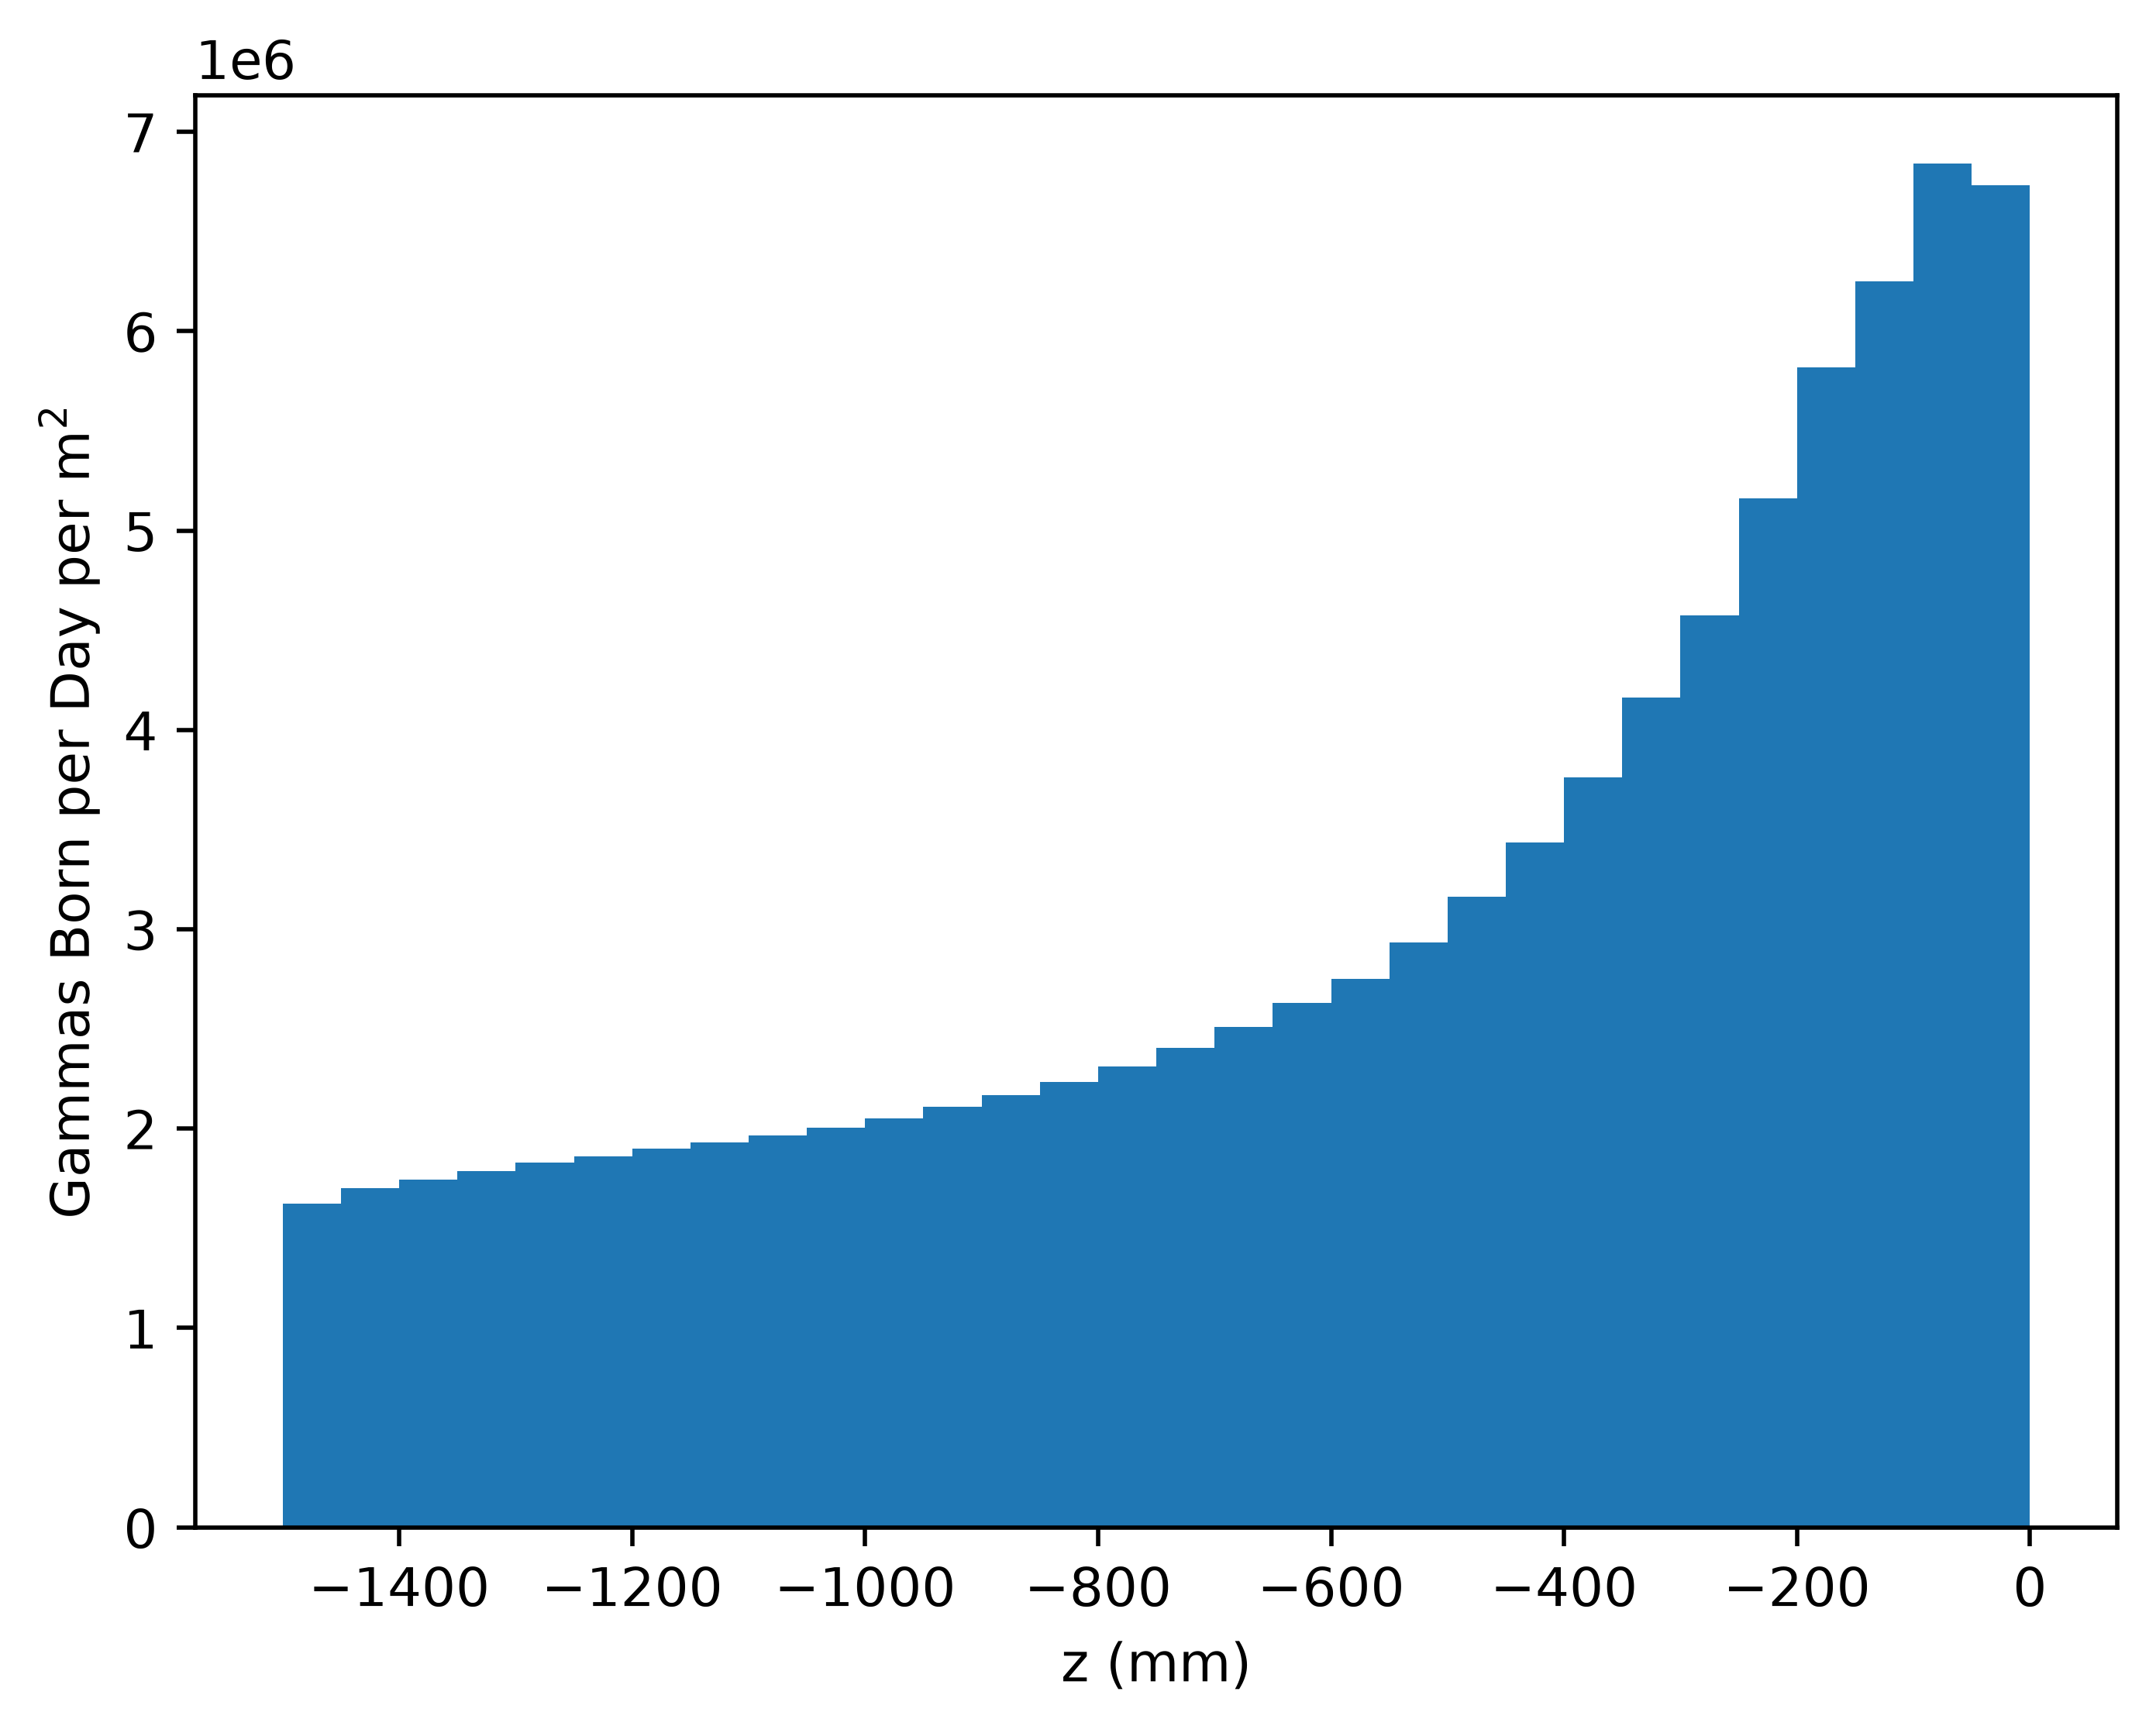

In [8]:
plot_with_peaks(df["z"], n_bins=30, weights=df["w"], bin_range=(-1500, 0), xlabel="z (mm)")  # V4: 5 cm depth bins

In [9]:
# df[include_processes(["", "neutronInelastic"])]["z"].agg(["mean", "sem"])
inelastic = df["creator"].astype(str).str.startswith("inelastic")  # V4: inelastic reactions on any nucleus
weighted_stats(df[inelastic]["z"], df[inelastic])[["mean", "sem"]]

mean   -606.760644
sem       0.408756
dtype: float64

## Energy Spectrum

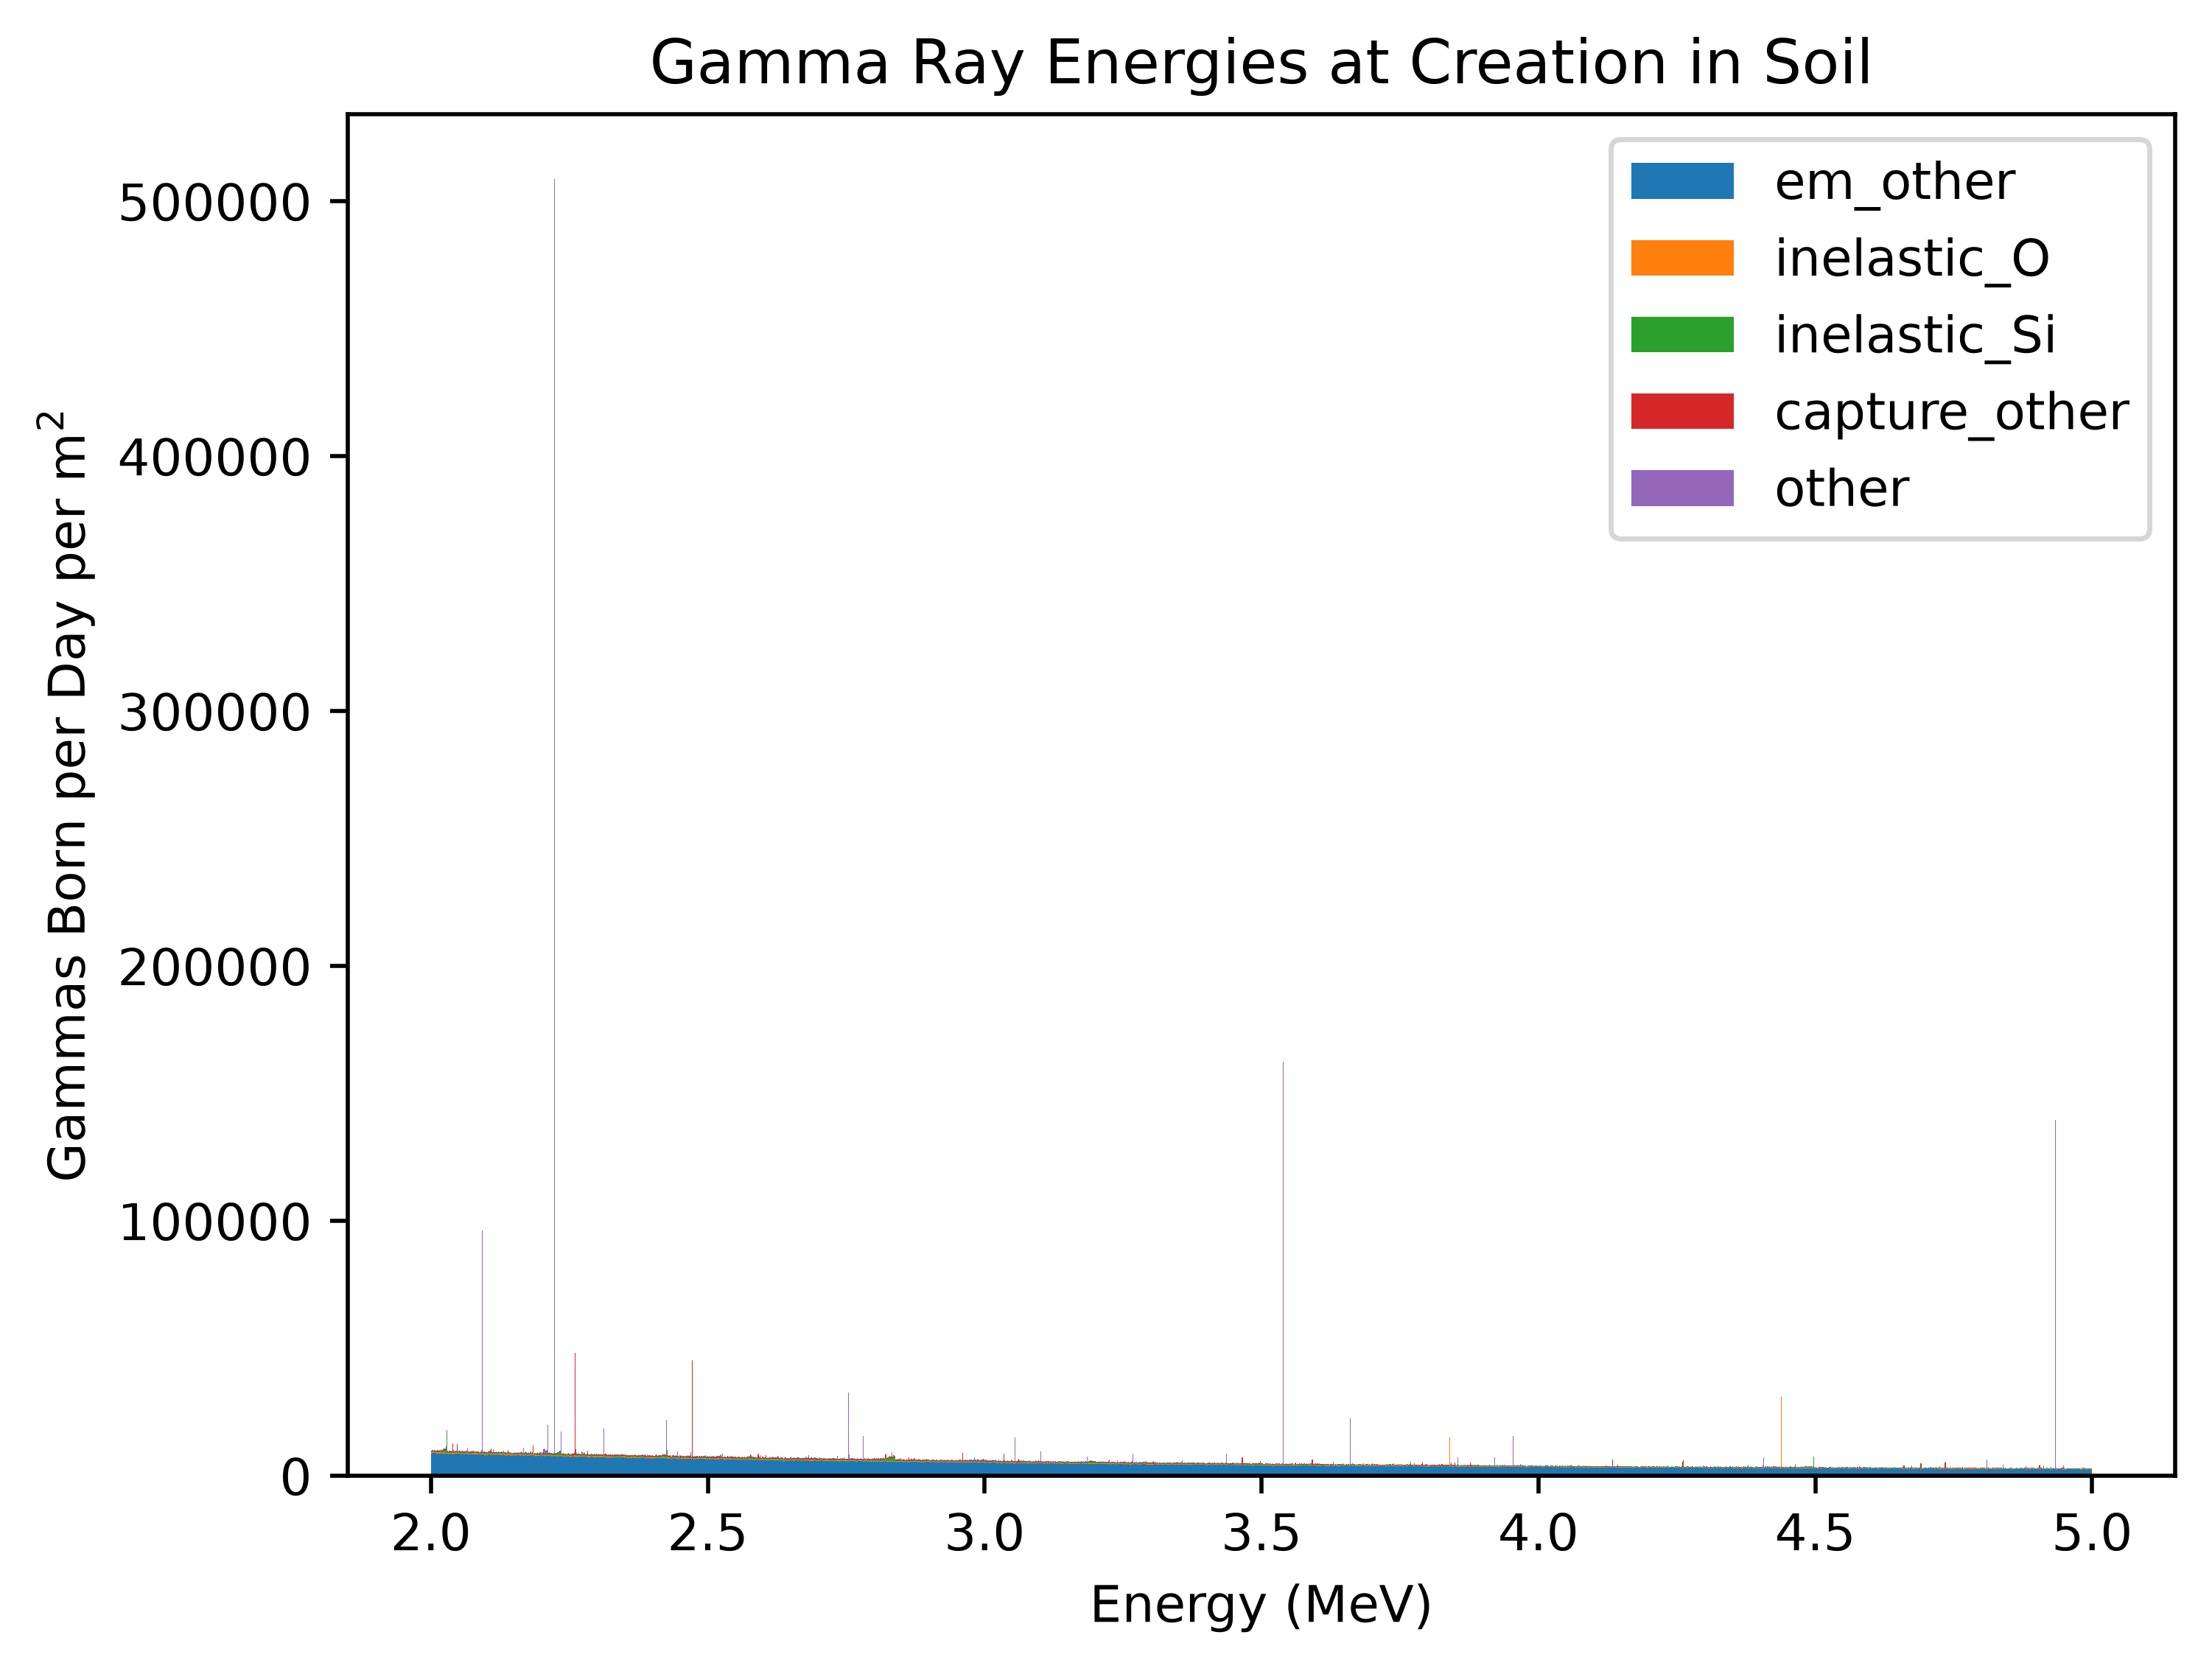

In [10]:
def plot_energy_spectrum(
    e_low, e_high, n_bins=512, prominence=None, clip=None, text_size=5
):
    rows = lambda procs: df[energy_range(e_low, e_high) & include_processes(procs)]
    plot_with_peaks(
        data=[rows([proc])["E"] for proc in process_names[:4]]
        + [rows(process_names[4:])["E"]],
        weights=[rows([proc])["w"] for proc in process_names[:4]]
        + [rows(process_names[4:])["w"]],
        n_bins=n_bins,
        # prominence=prominence,
        xlabel="Energy (MeV)",
        title="Gamma Ray Energies at Creation in Soil",
        clip_counts=clip,
        text_size=text_size,
        divide=exposure,
        stacked=True,
        bin_range=(e_low, e_high),
        legend=list(process_names[:4]) + ["other"],
    )


plot_energy_spectrum(
    2.0, 5.0, clip=500000, n_bins=3000, prominence=100000, text_size=10
)
# plot_energy_spectrum(0.5, 0.6, n_bins=256, prominence=200000, text_size=10)

# Not available for V4: the 0.511 MeV breakdown by cosmic source particle (not in the reduced data)
# annihil_sources, annihil_counts = np.unique(df[energy_range(0.510, 0.512)]["source"], return_counts=True)
#
# plt.bar(annihil_sources, annihil_counts / annihil_counts.sum())
#
# for source, prop in zip(annihil_sources, annihil_counts / annihil_counts.sum()):
#     print(f"{source}: {prop:%}")

In [11]:
# V4: whole-keV windows (bin centres are at x.5 keV). The 4.438 bin is the line from 16O(n,n'a)12C*,
# the 4.439 bin the line from carbon itself (see the class breakdown below).
mask_4438 = energy_range(4.438, 4.439)
mask_4439 = energy_range(4.439, 4.440)
print(df[mask_4438 | mask_4439].groupby([df["E"].round(4), "creator"], observed=True)["w"].sum().loc[lambda s: s > 1])

E       creator        
4.4385  capture_other         54.594289
        decay                 19.199974
        em_other            2789.756157
        inelastic_Al          13.439981
        inelastic_C          616.319151
        inelastic_Fe          15.359979
        inelastic_O        27066.202717
        inelastic_Si         151.679791
        inelastic_other       63.359913
4.4395  capture_other        103.122546
        decay                  5.759992
        em_other            2943.355946
        inelastic_Al           5.759992
        inelastic_C         1749.117591
        inelastic_Fe           7.679989
        inelastic_O          220.799696
        inelastic_Si         126.719825
        inelastic_other       49.919931
Name: w, dtype: float64


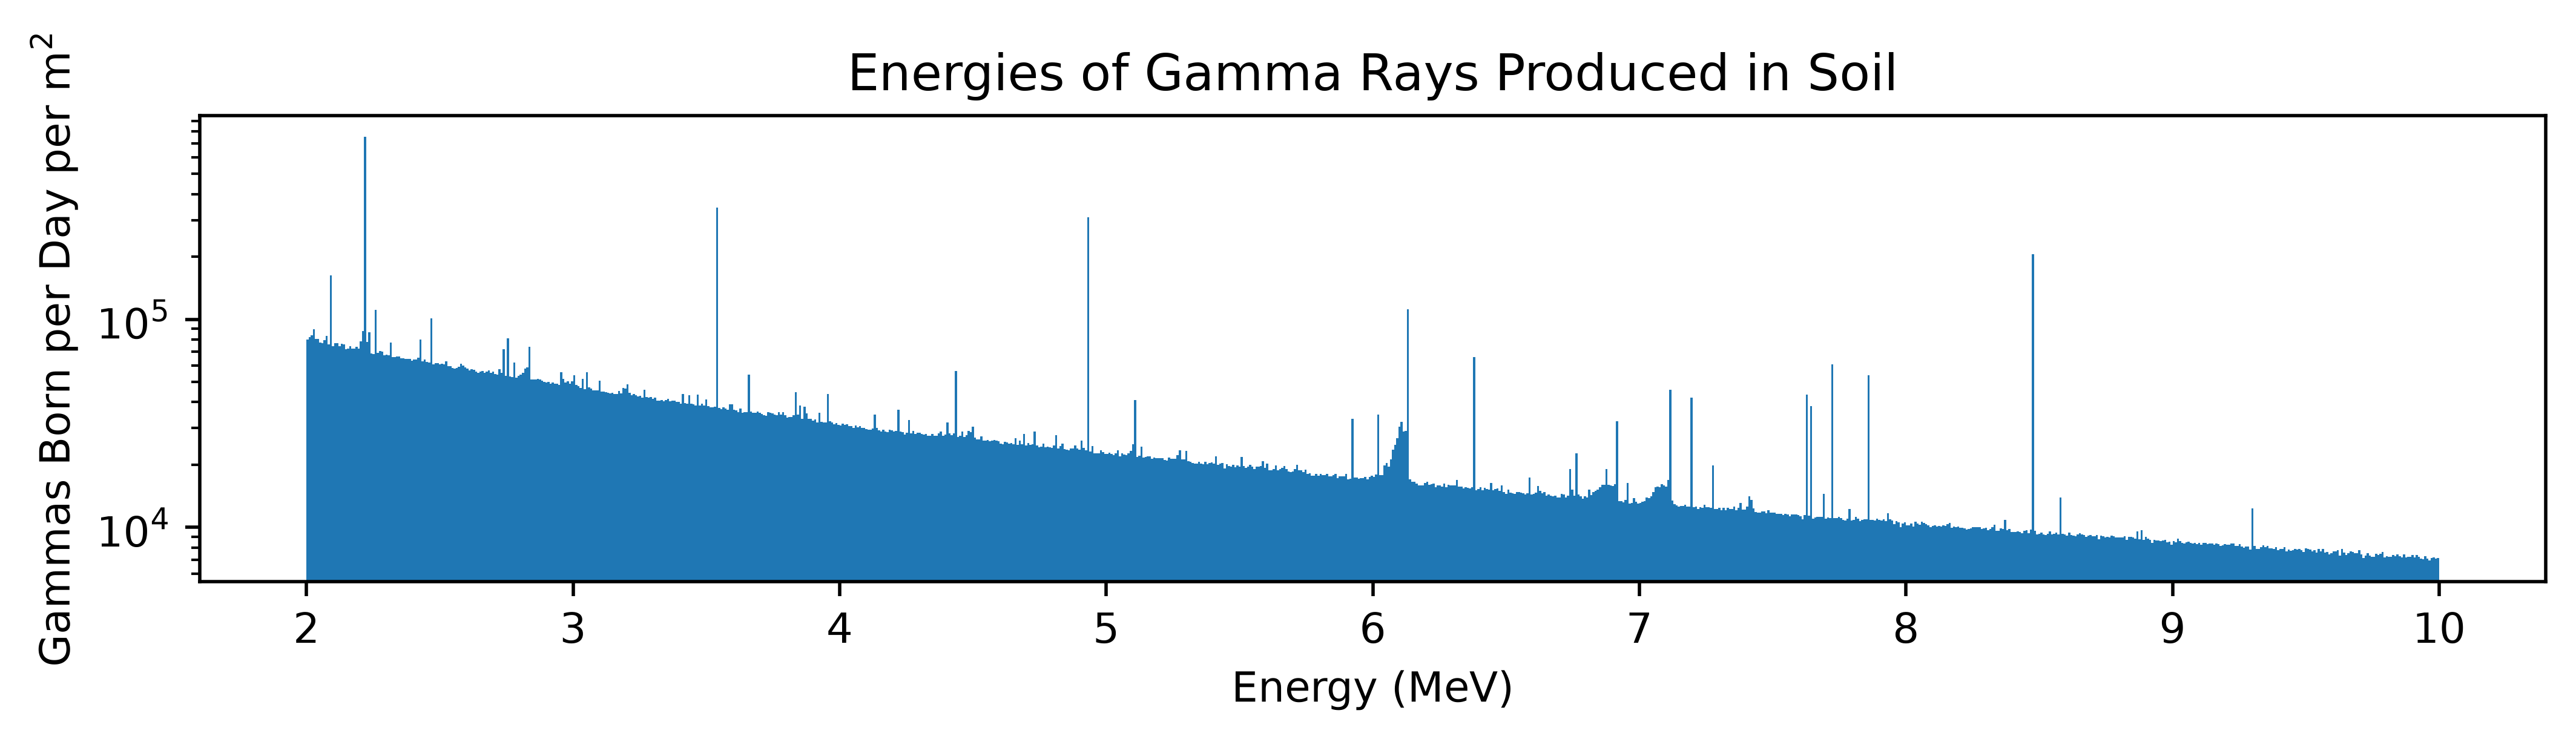

In [12]:
plt.figure(figsize=(10, 2))
plt.yscale("log")
plot_with_peaks(
    df[energy_range(2.0, 10.0)]["E"],
    1000,
    weights=df[energy_range(2.0, 10.0)]["w"],  # V4
    bin_range=(2.0, 10.0),  # V4: align the bins with the 1 keV data
    # prominence=30000,
    xlabel="Energy (MeV)",
    divide=exposure,
    # text_size=3,
    title="Energies of Gamma Rays Produced in Soil",
    # rng_weight=400000.0
)
# plt.annotate("2.223 MeV", (2.223, 10e6))
plt.show()

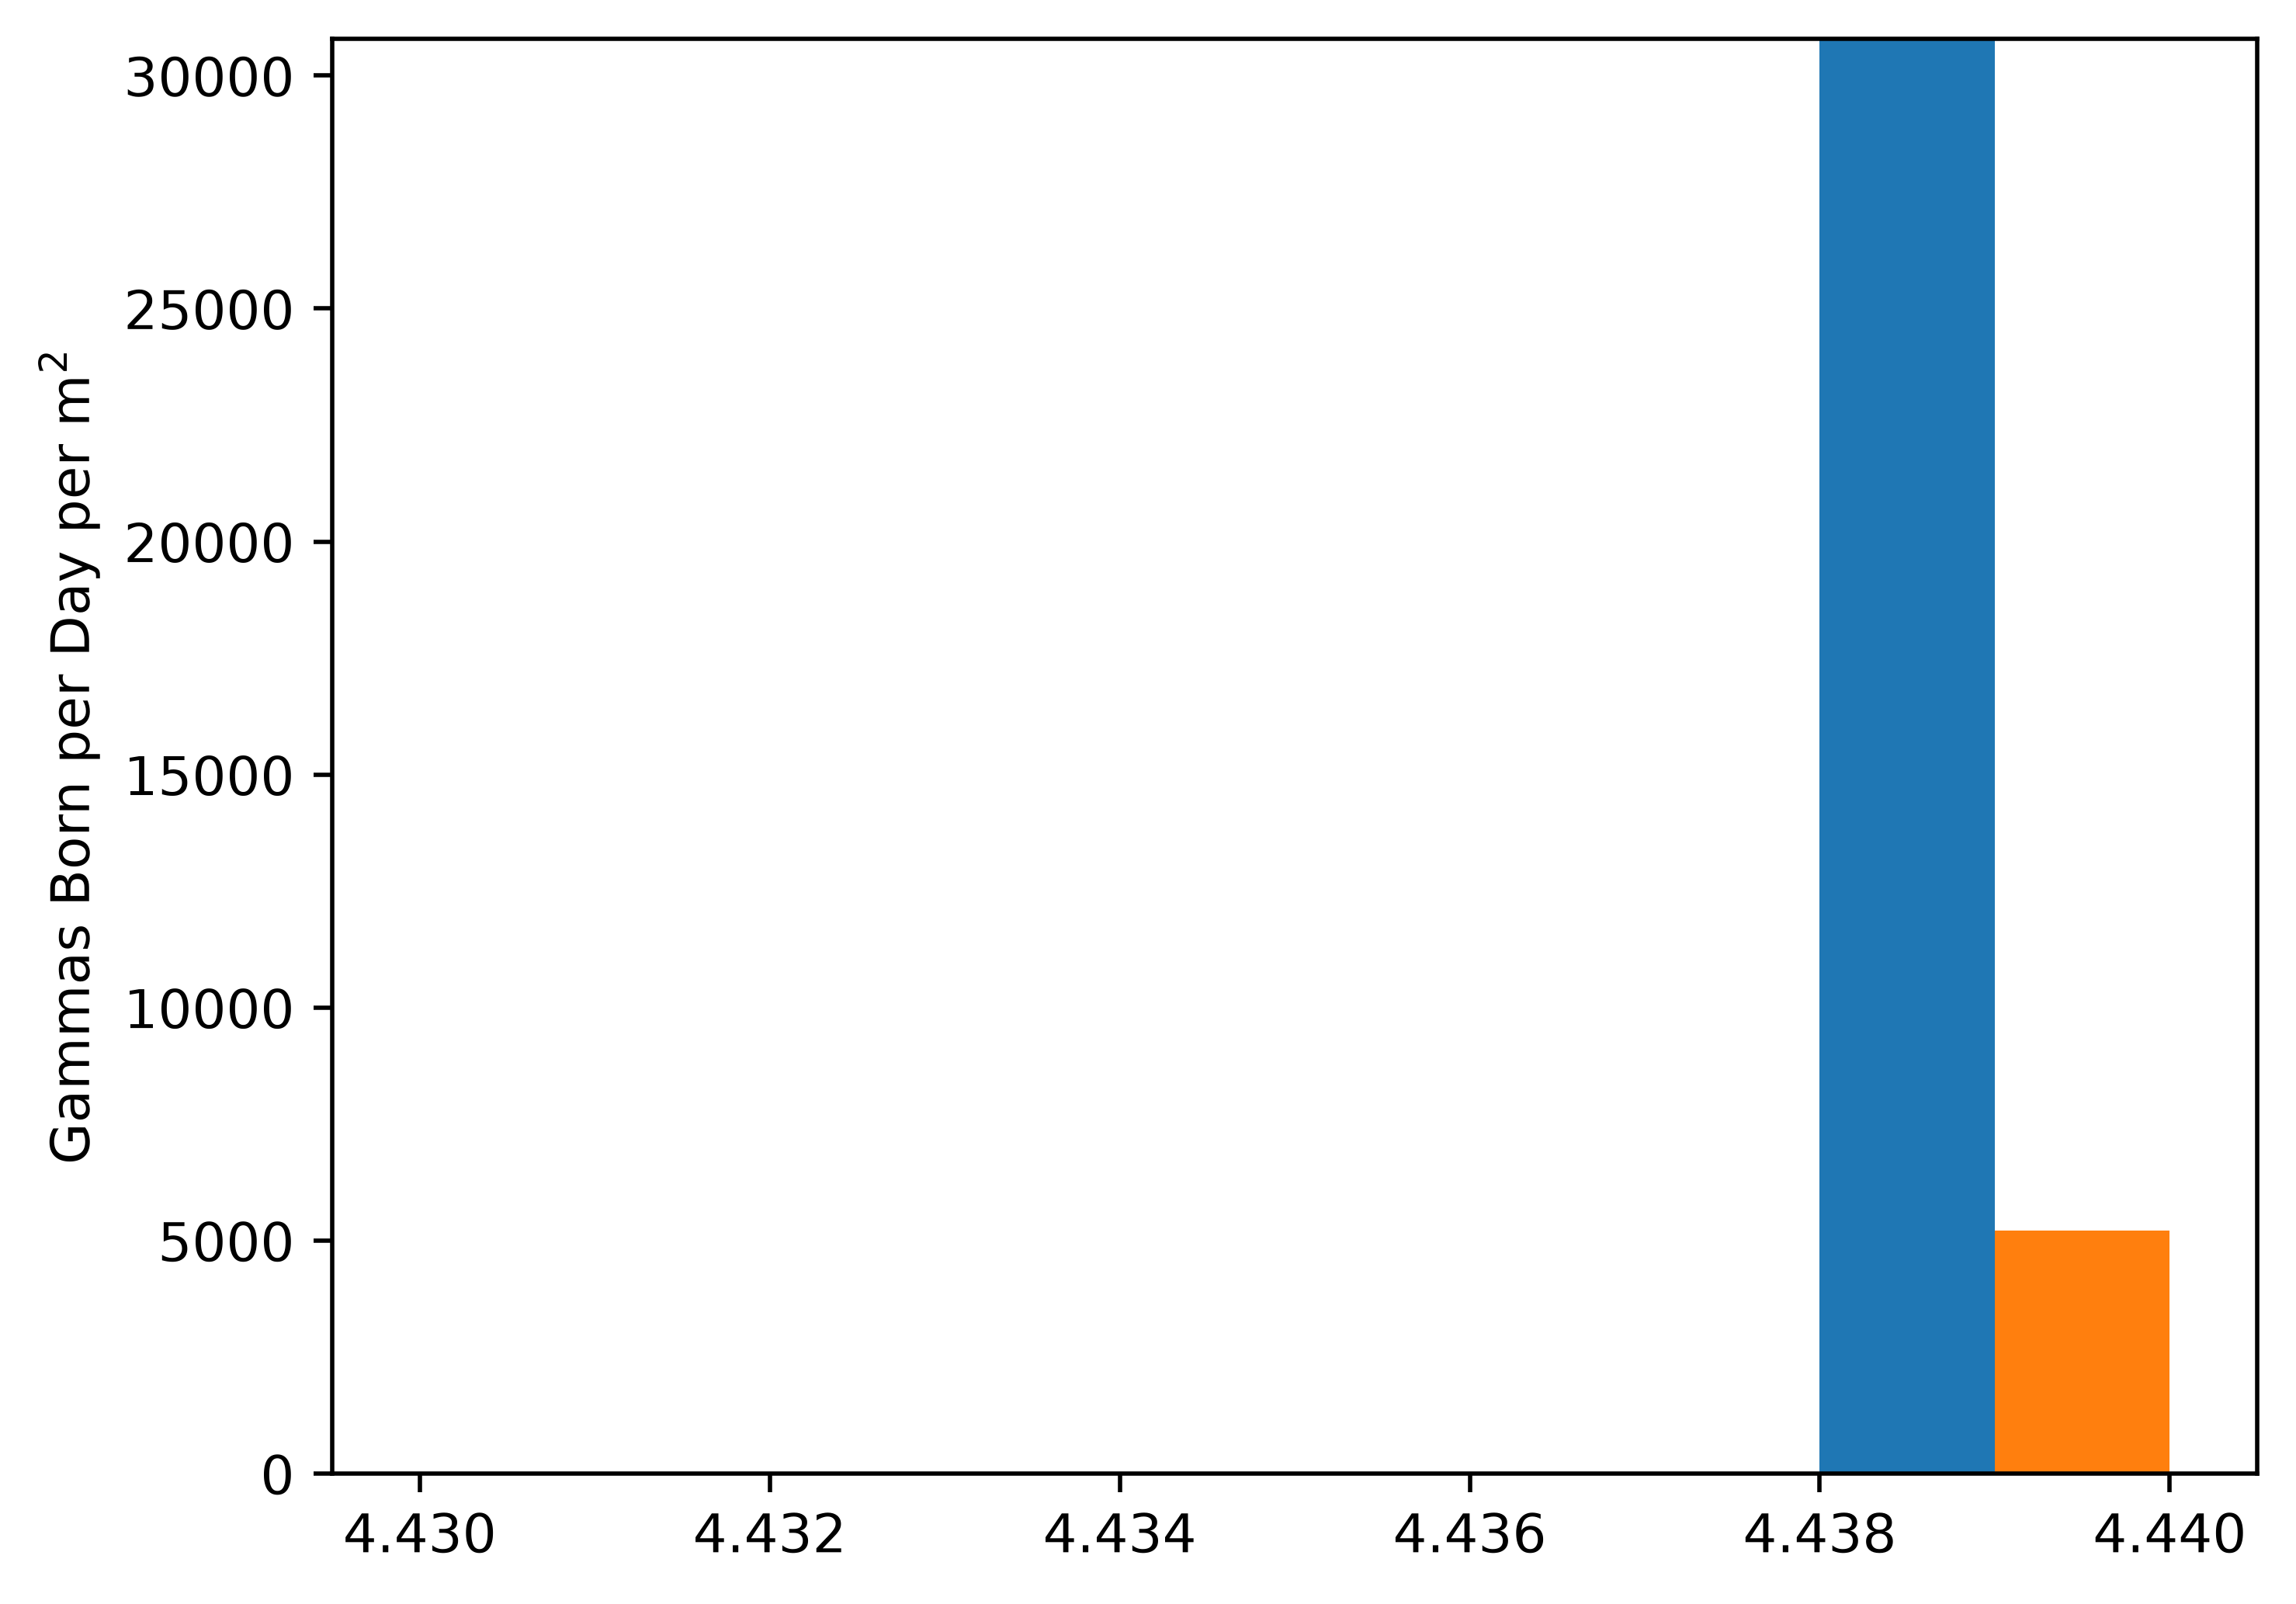

In [13]:
plot_with_peaks(
    [df[mask_4438]["E"], df[mask_4439]["E"]],
    10,  # V4: 1 keV bins
    weights=[df[mask_4438]["w"], df[mask_4439]["w"]],
    stacked=True,
    bin_range=(4.43, 4.44),
)
# df[""]

## Depth Profiles

In [14]:
name_dict = {
    "annihil": "Annihilation",
    "neutronInelastic": "Inelastic Neutron Scattering",
    "nCapture": "Neutron Capture",
    "RadioactiveDecay": "Radioactive Decay",
    "protonInelastic": "Inelastic Proton Scattering",
    "eBrem": "Bremsstrahlung",
    "gamma": "Gamma",
    "muMinusCaptureAtRest": "$\\mu^{-}$ Capture at Rest",
    # V4 origin classes ("inelastic" = any non-capture hadronic reaction, incl. muon capture)
    "em_other": "EM (Brems., Annihilation, ...)",
    "capture_H": "n Capture on H",
    "capture_Si": "n Capture on Si",
    "capture_Fe": "n Capture on Fe",
    "capture_other": "n Capture, Other",
    "inelastic_C": "Inelastic on C",
    "inelastic_O": "Inelastic on O",
    "inelastic_Si": "Inelastic on Si",
    "inelastic_Fe": "Inelastic on Fe",
    "inelastic_Al": "Inelastic on Al",
    "inelastic_other": "Inelastic, Other",
    "decay": "Radioactive Decay",
}

# Not available for V4: split by cosmic source particle (not in the reduced data)
# plt.figure(figsize=(10, 2))
# plt.yscale("log")
# plot_with_peaks(
#     data=[
#         df[energy_range(2.0, 10.0) & exclude_sources(["neutron"])]["E"],
#         df[energy_range(2.0, 10.0) & include_sources(["neutron"])]["E"],
#     ],
#     n_bins=1000,
#     xlabel="Energy (MeV)",
#     title="Energies of Gamma Rays Produced in Soil, by Source Cosmic Ray Particle",
#     xlims=(2.0, 10.0),
#     stacked=True,
#     legend=["All Others", "Neutrons"],
#     bin_range=(2.0, 10.0),
#     divide=exposure,
#     text_size=3,
# )

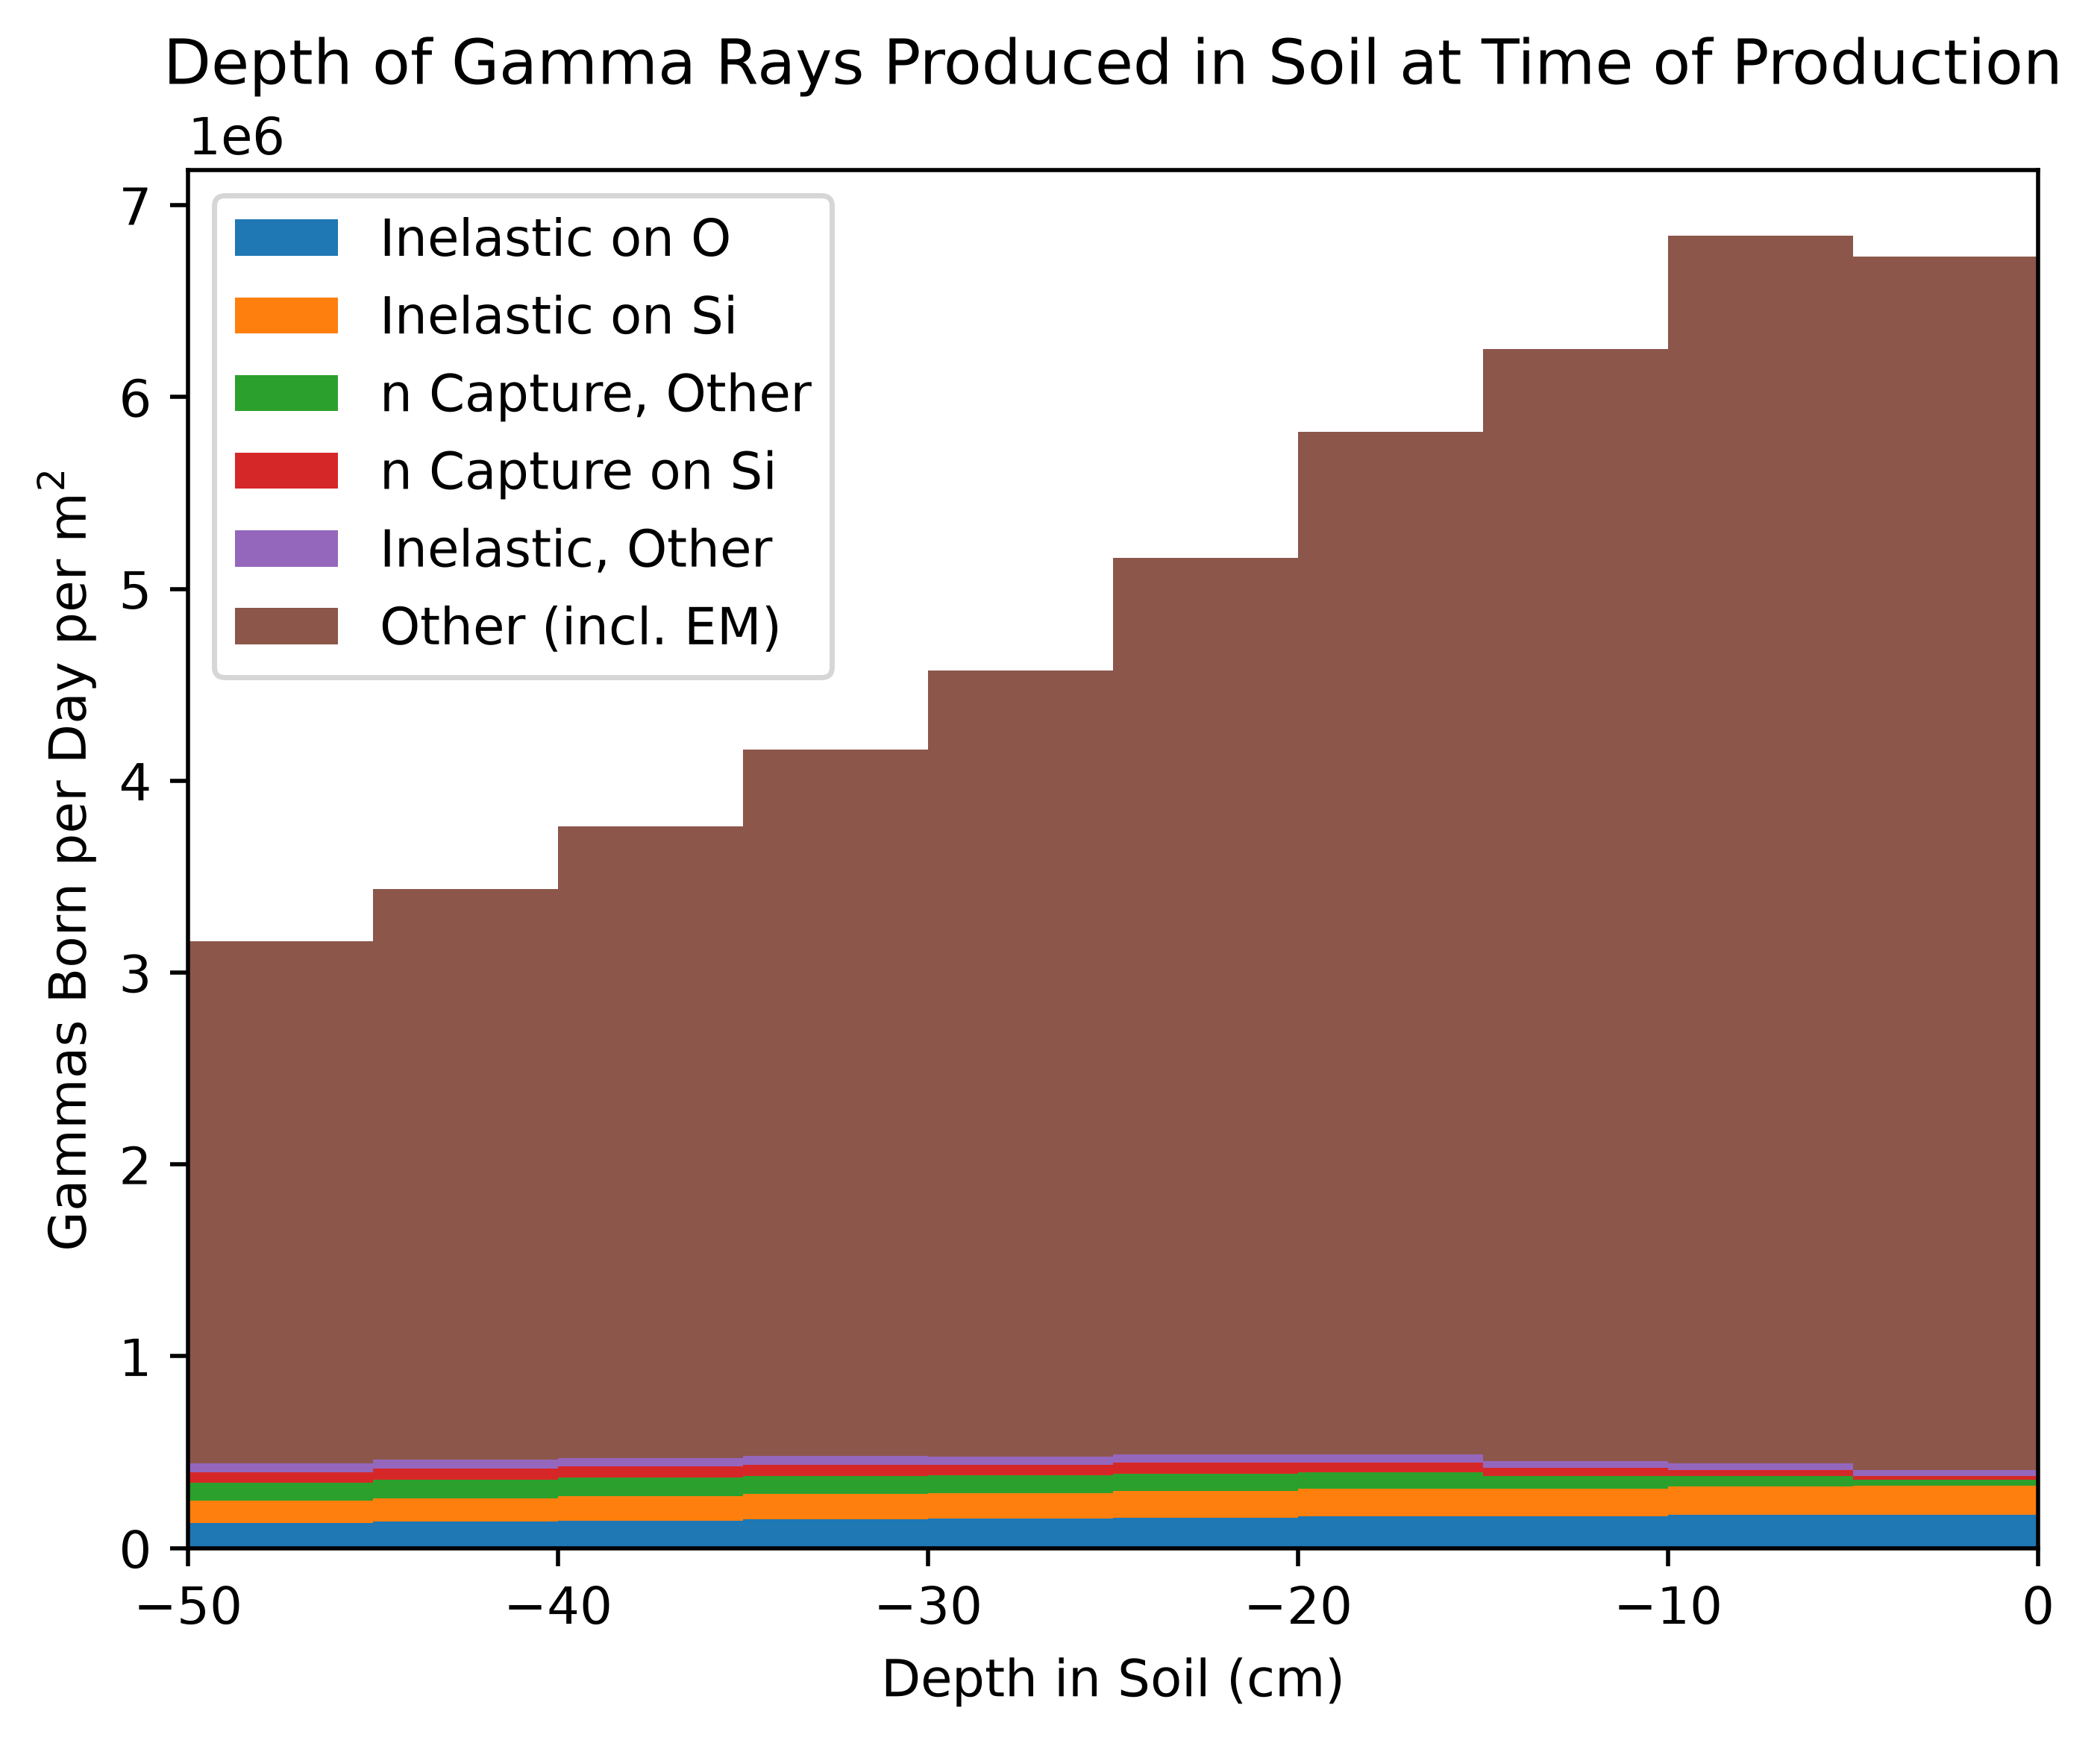

In [15]:
# plt.yscale("log")

plot_with_peaks(
    data=[df[include_processes([name])]["z"] / 10 for name in process_names[1:6]]
    + [df[exclude_processes(process_names[1:6])]["z"] / 10],
    weights=[df[include_processes([name])]["w"] for name in process_names[1:6]]
    + [df[exclude_processes(process_names[1:6])]["w"]],
    n_bins=10,  # V4: 5 cm depth bins
    xlabel="Depth in Soil (cm)",
    title="Depth of Gamma Rays Produced in Soil at Time of Production",
    xlims=(-50, 0),
    stacked=True,
    legend=list(name_dict[name] for name in process_names[1:6]) + ["Other (incl. EM)"],
    bin_range=(-50, 0),
    divide=exposure,
)

In [16]:
capture = df["creator"].astype(str).str.startswith("capture")  # V4: neutron capture on any nucleus
print(weighted_stats(df[capture]["z"], df[capture])[["mean", "std", "sem"]])

# Not available for V4: depth by cosmic source particle (not in the reduced data)
# plt.ylim(0, 150000)
# plot_with_peaks(
#     data=[df[exclude_processes([]) & include_sources([name])]["z"] / 10 for name in source_names[:]],
#     n_bins=256,
#     xlabel="Depth (cm)",
#     title="Depth of Non-Primary Gamma Rays at Creation, by Original Source",
#     xlims=(-50, 0),
#     stacked=True,
#     legend=list(source_names[:]),
#     bin_range=(-50, 0),
# )

mean   -631.980982
std     362.882658
sem       0.559263
dtype: float64


{'capture_other': 309.4, 'decay': 223919.7, 'em_other': 10448.6, 'inelastic_Al': 42.2, 'inelastic_C': 1.9, 'inelastic_Fe': 15.4, 'inelastic_O': 501.1, 'inelastic_Si': 40200.9, 'inelastic_other': 142.1}


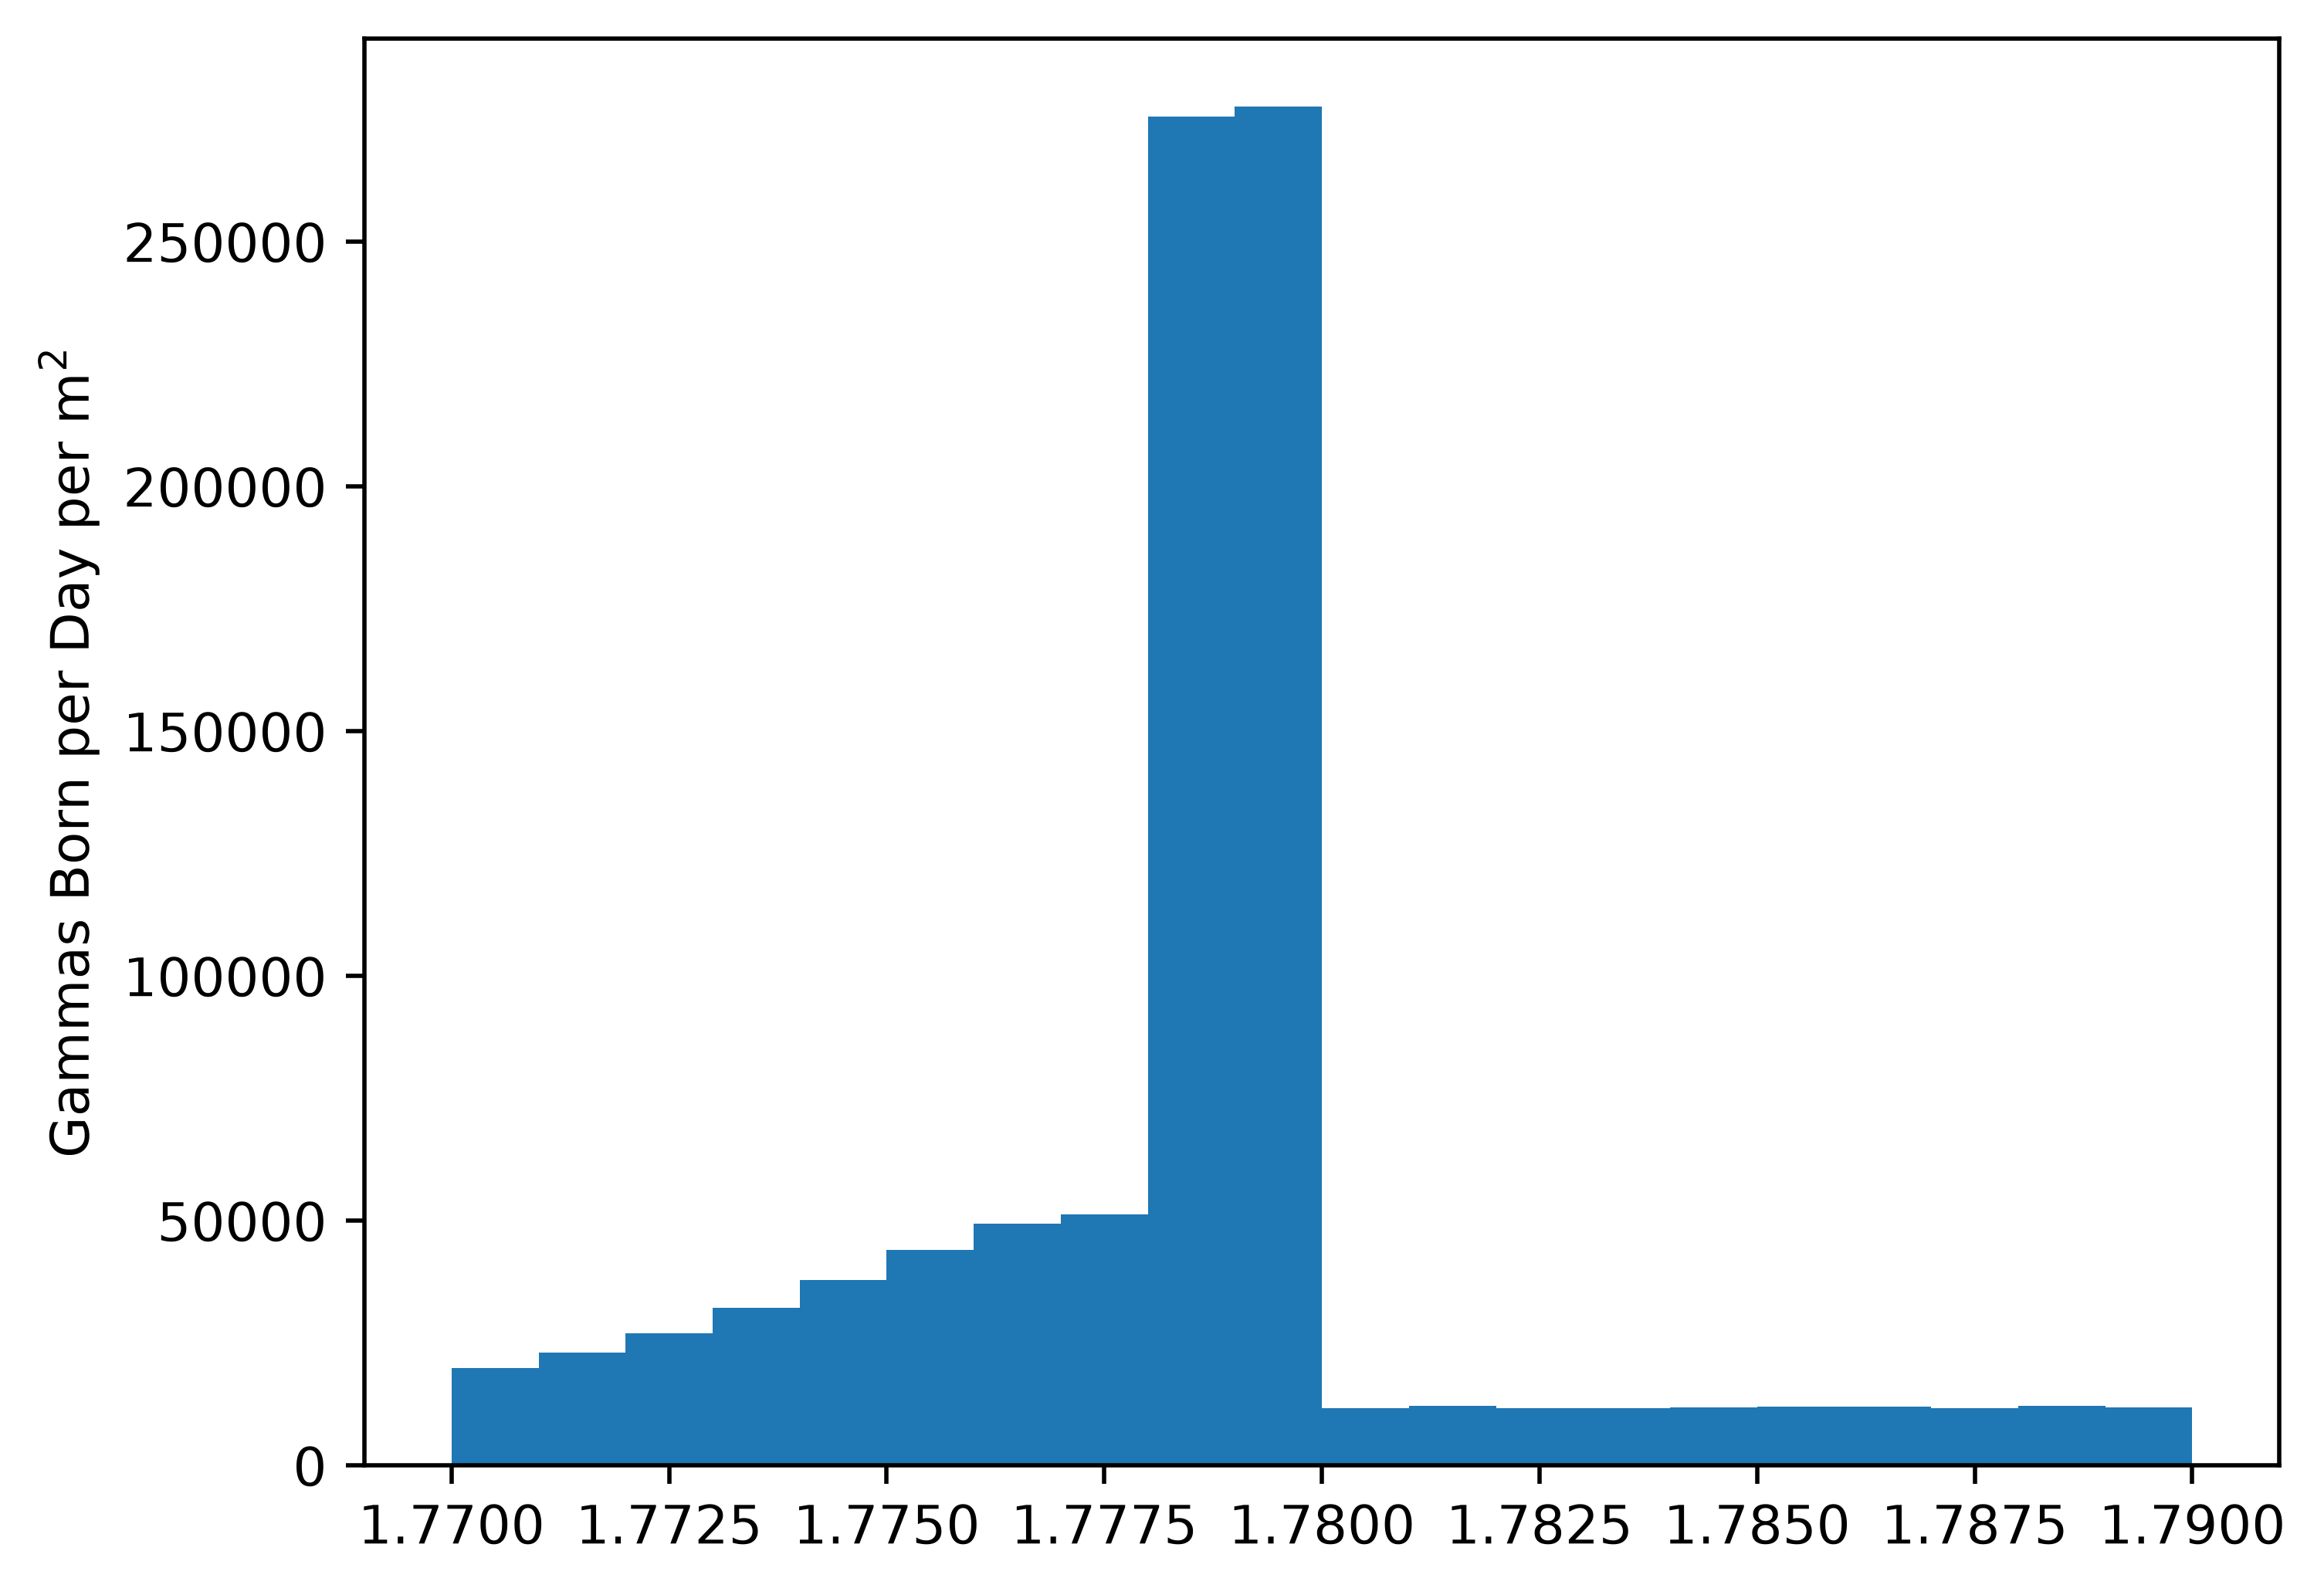

In [17]:
mask_1779 = energy_range(1.778, 1.779)  # V4: the 1 keV bin holding the 1.7790 MeV line
print(df[mask_1779].groupby("creator", observed=True)["w"].sum().loc[lambda s: s > 0].round(1).to_dict())
plot_with_peaks(df[energy_range(1.770, 1.790)]["E"], n_bins=20, weights=df[energy_range(1.770, 1.790)]["w"],
                divide=exposure, bin_range=(1.770, 1.790))

mean     -61.692149
median   -57.500000
std       39.444298
dtype: float64


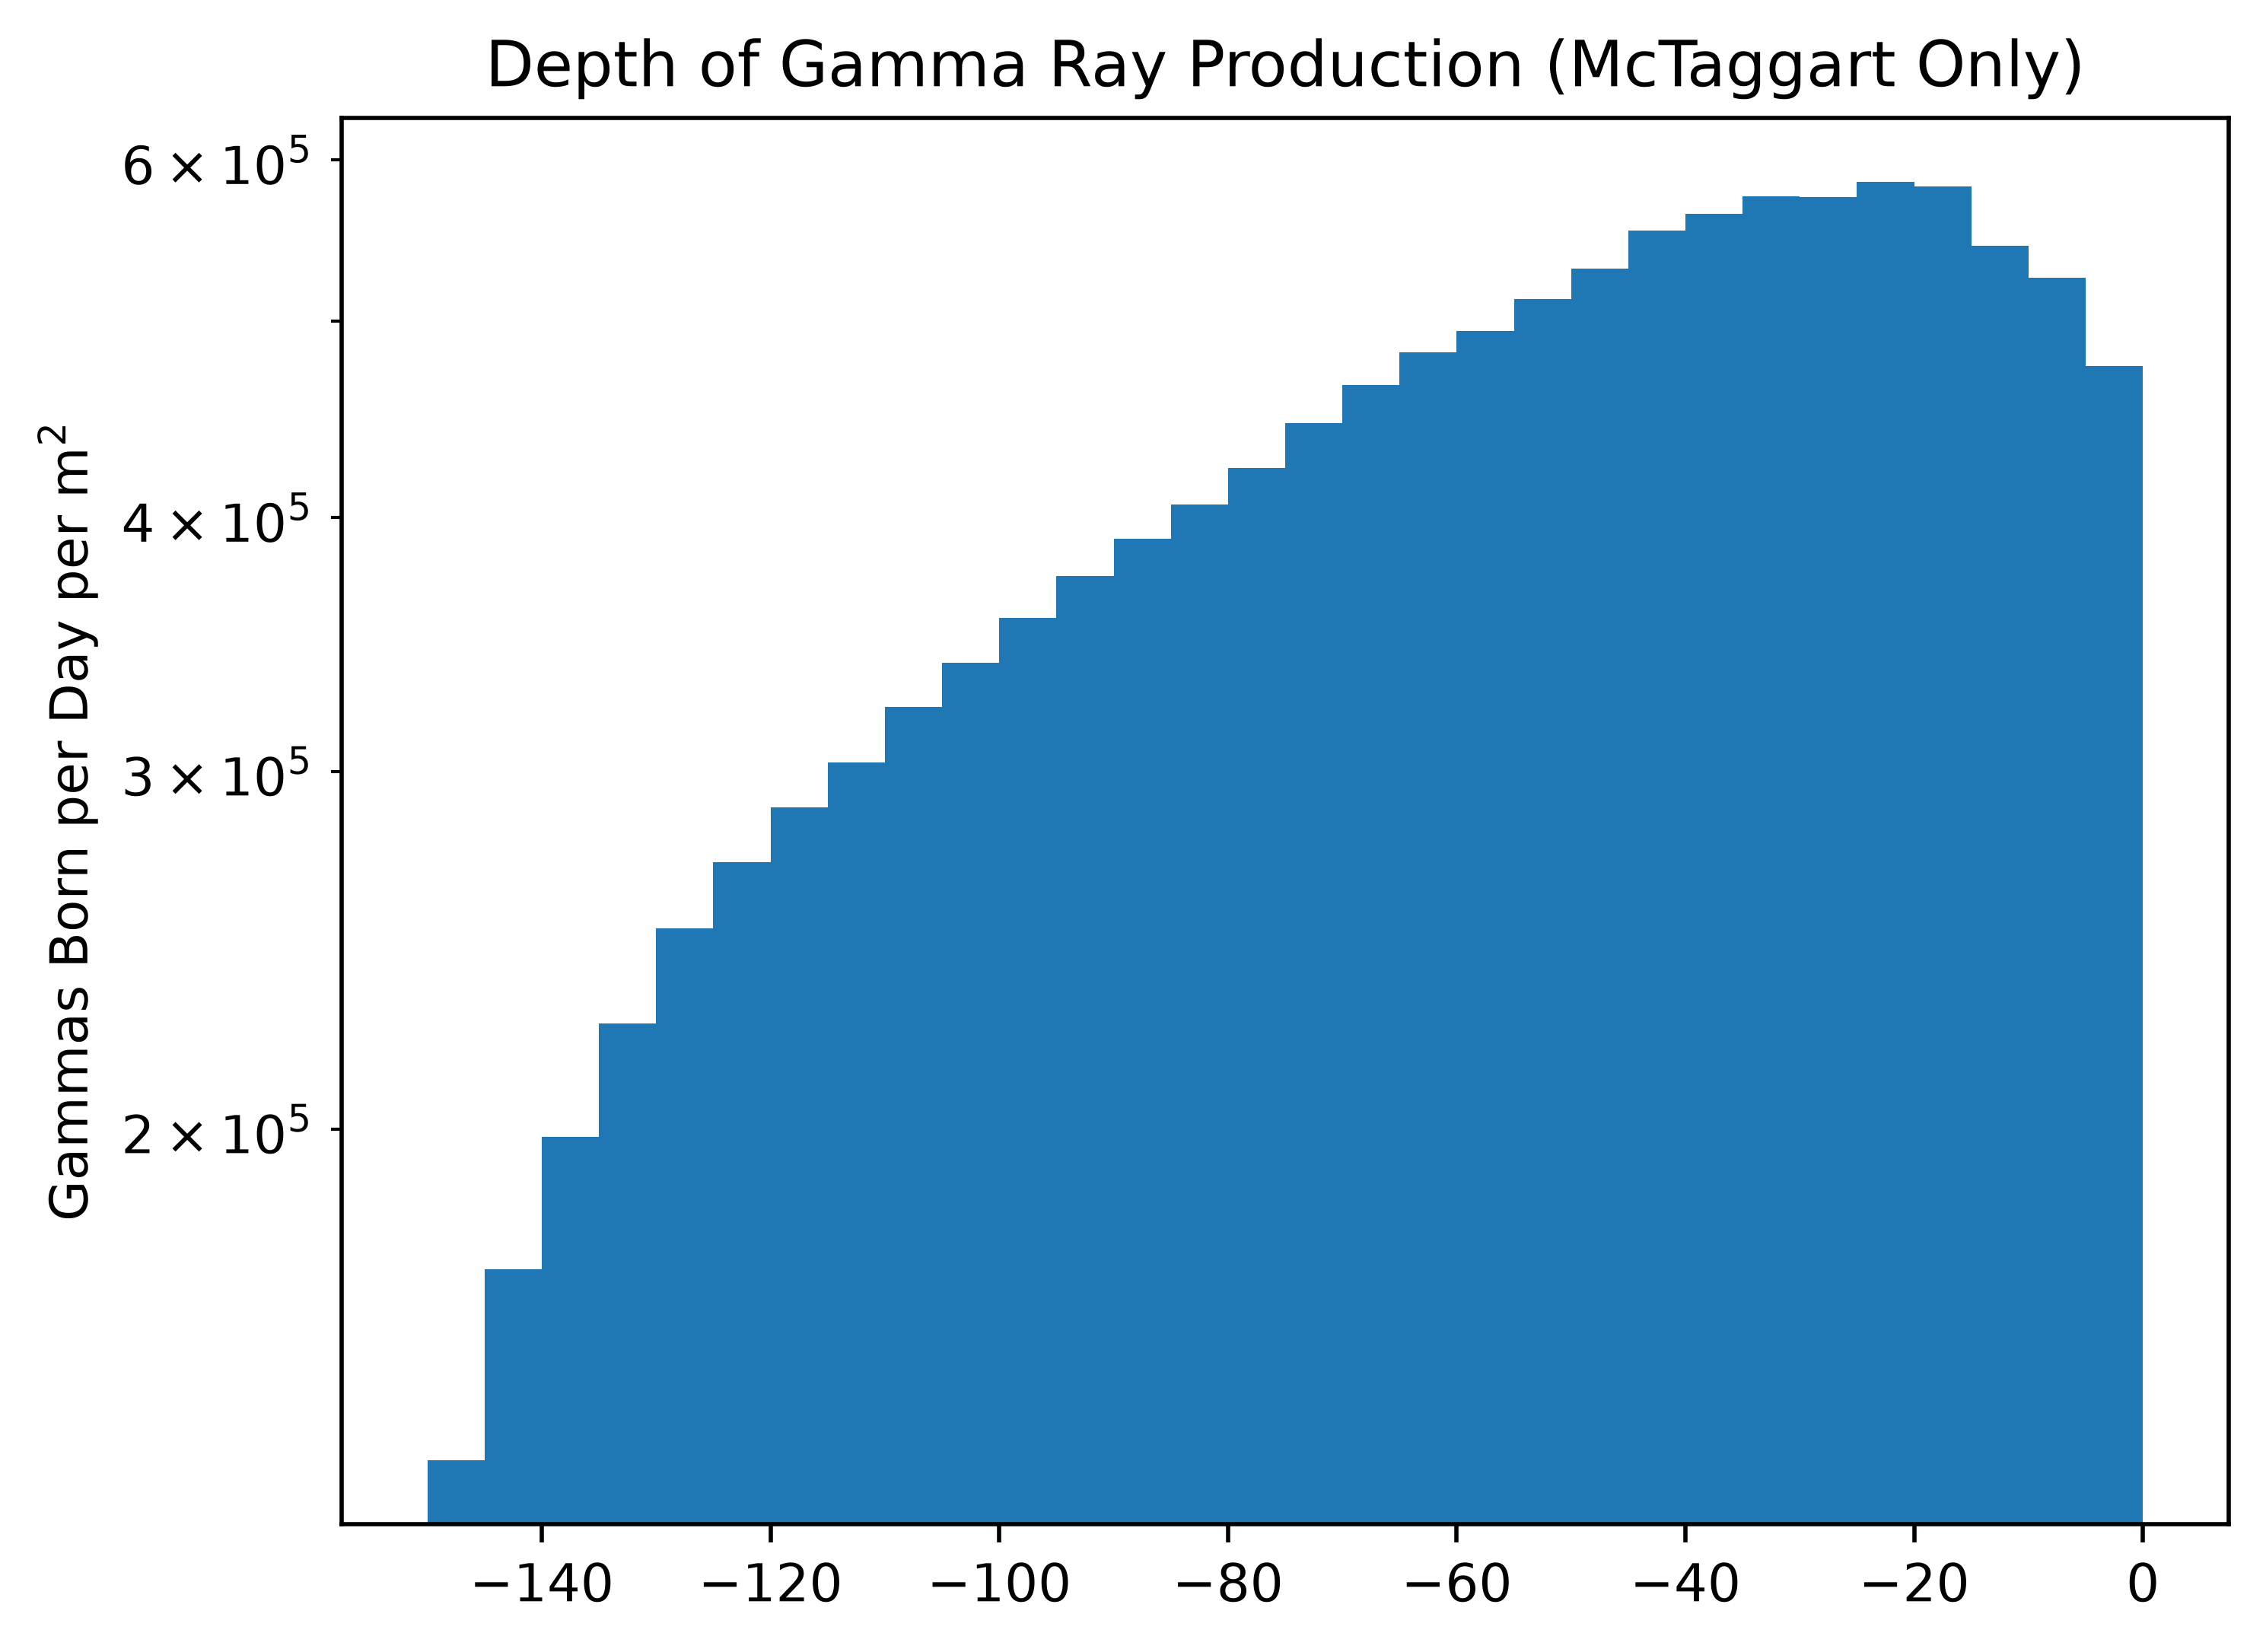

In [18]:
mctaggart = exclude_processes(["em_other"])  # V4: every capture, inelastic and decay class
print(weighted_stats(df[mctaggart]["z"], df[mctaggart])[["mean", "median", "std"]] / 10)
plt.yscale("log")
plot_with_peaks(
    df[mctaggart]["z"] / 10, 30, weights=df[mctaggart]["w"], bin_range=(-150, 0),
    title="Depth of Gamma Ray Production (McTaggart Only)"
)

## Creation Processes

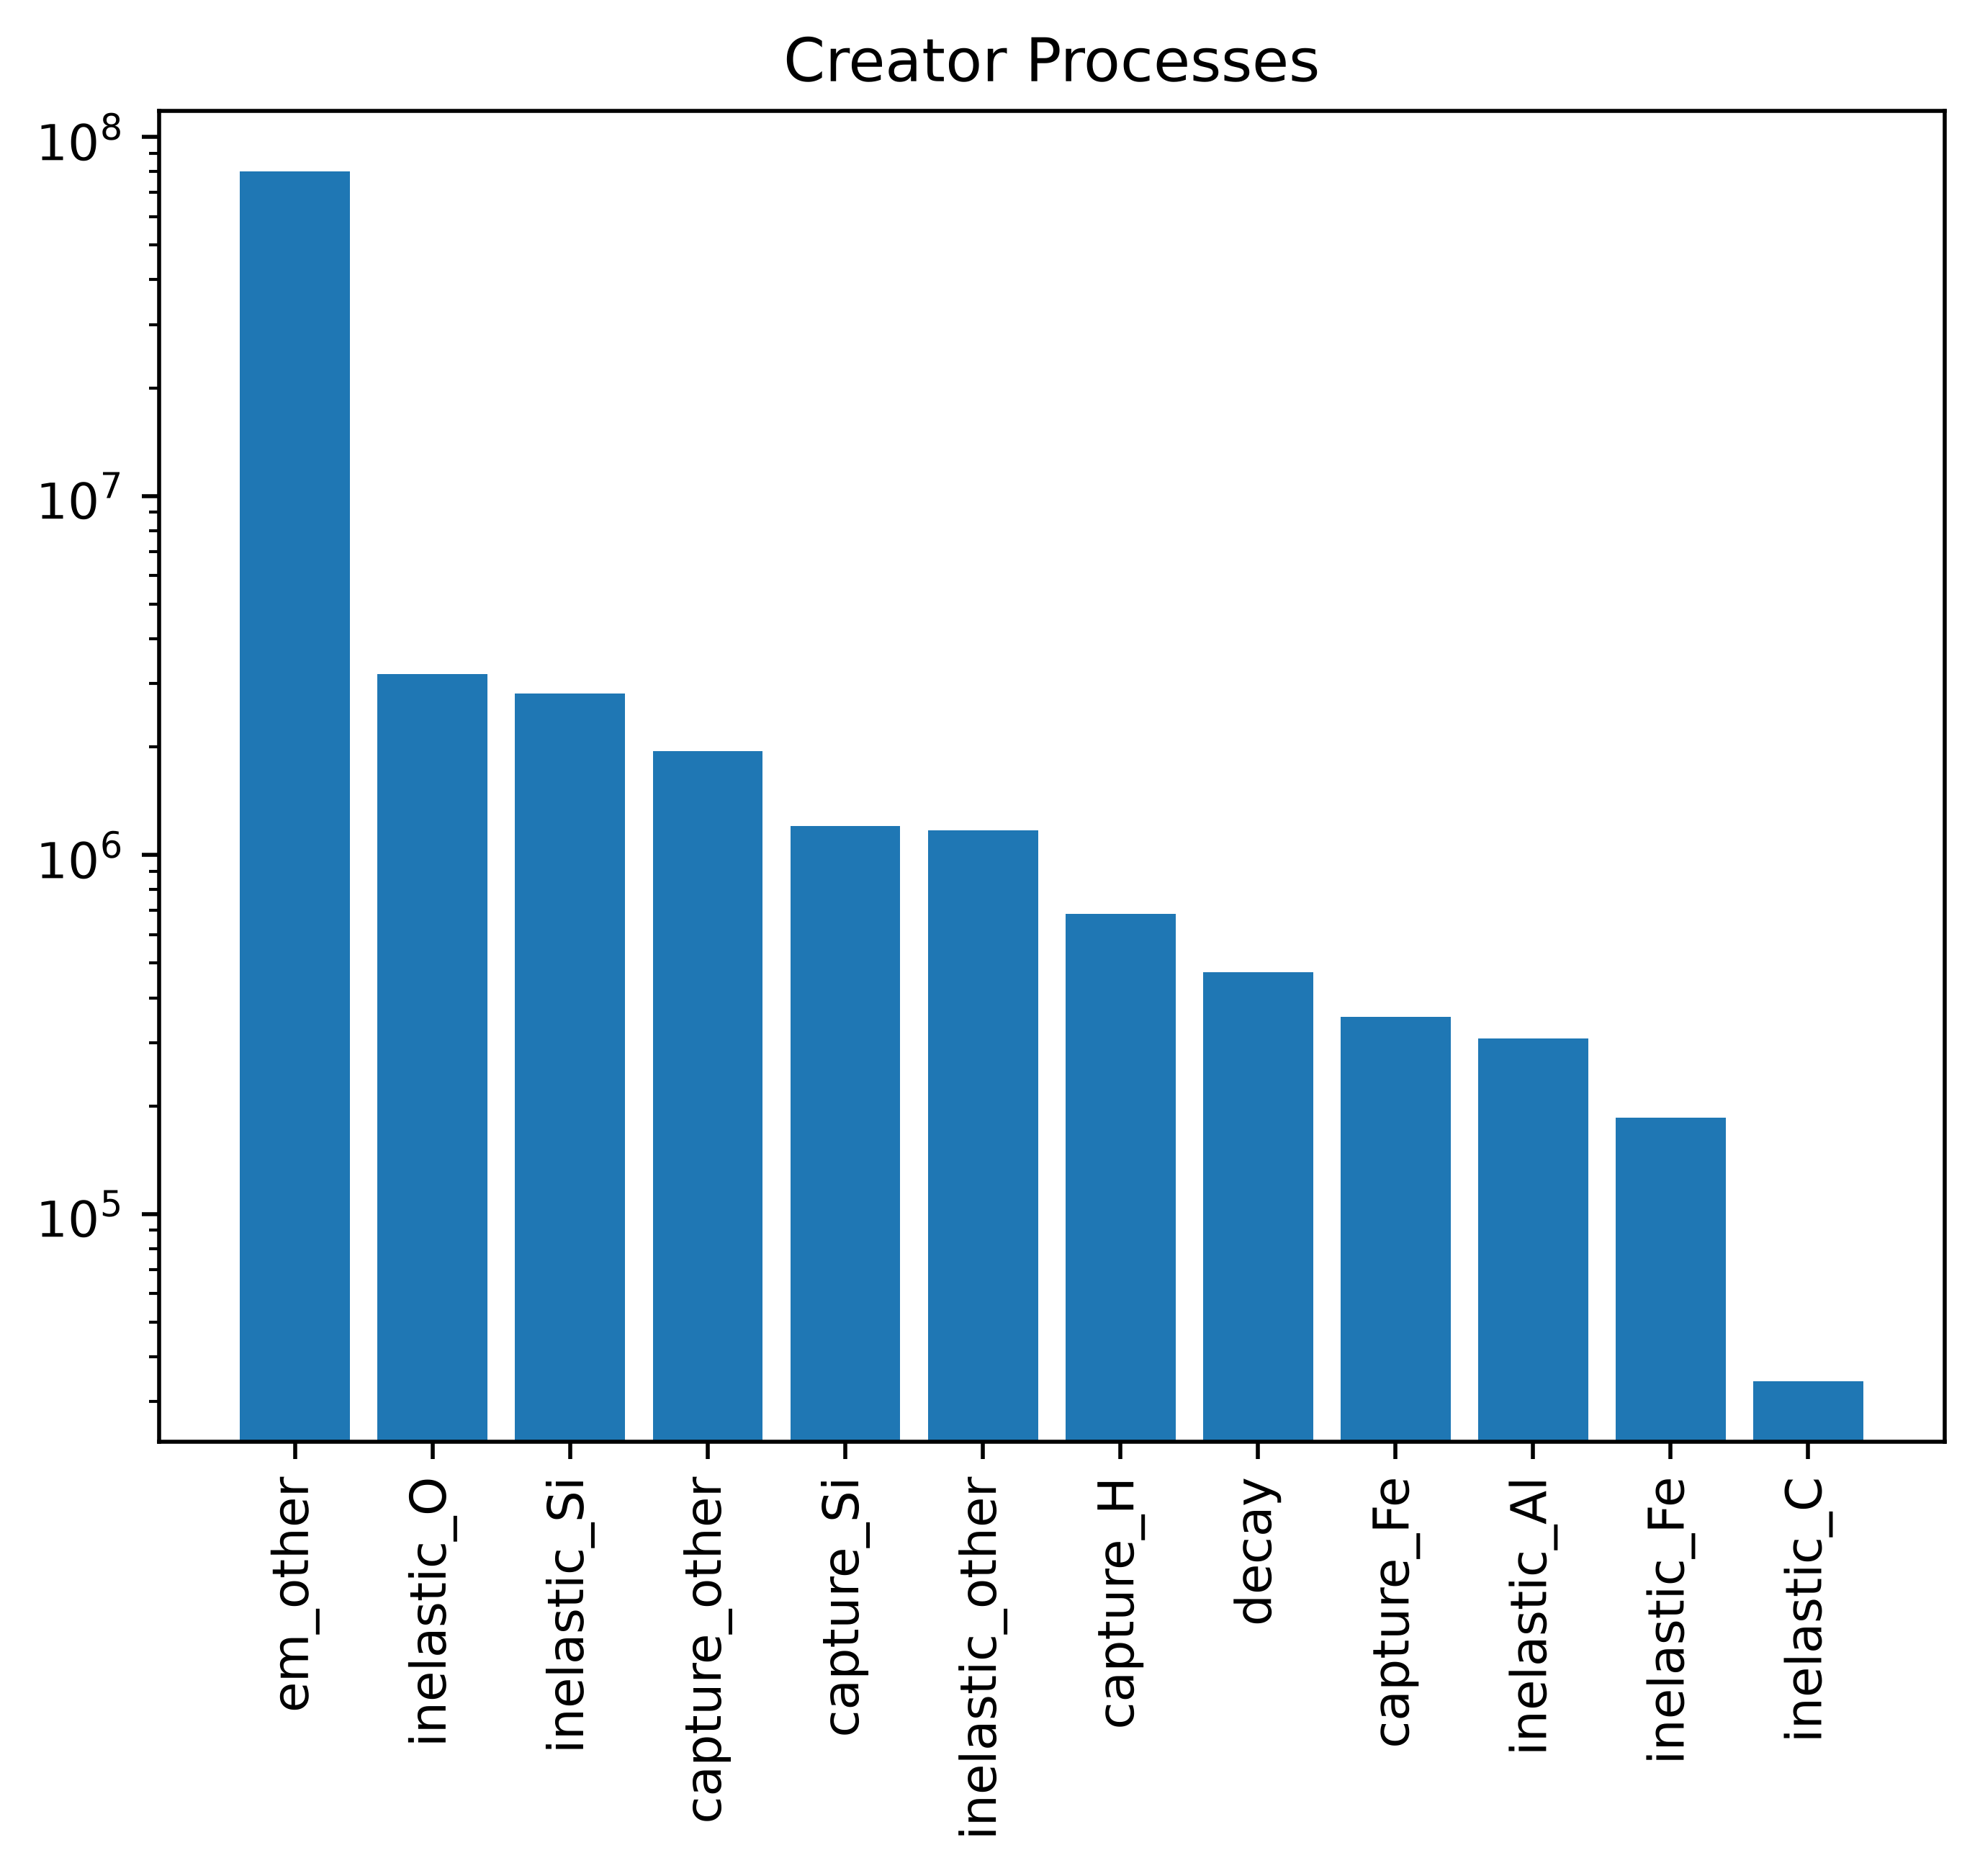

In [19]:
plt.yscale("log")
plt.bar(process_names, process_counts)
plt.xticks(rotation="vertical")
plt.title("Creator Processes")
plt.show()

In [20]:
def process_breakdown(df):
    # V4: shares of the (capture-corrected) weights; errors from the simulated counts n,
    # inflated for the several gammas each shower makes
    totals = df.groupby("creator", observed=True)[["w", "n"]].sum().sort_values("w", ascending=False)
    shares = totals["w"] / totals["w"].sum()
    uncerts = shares * np.sqrt(L.BIRTH_CLUSTER / totals["n"].clip(lower=1))
    for name, pc, pc_u in zip(totals.index, shares, uncerts):
        print(f"{name} & {100*pc:.04f}\\% & {100*pc_u:.04f}\\% \\\\")

# process_breakdown(df[df["source"] == "neutron"])  # V4: no cosmic source particle in the reduced data
# print()
process_breakdown(df)

em_other & 86.6095\% & 0.0268\% \\
inelastic_O & 3.4559\% & 0.0054\% \\
inelastic_Si & 3.0454\% & 0.0050\% \\
capture_other & 2.1093\% & 0.0053\% \\
capture_Si & 1.3033\% & 0.0041\% \\
inelastic_other & 1.2676\% & 0.0032\% \\
capture_H & 0.7419\% & 0.0020\% \\
decay & 0.5113\% & 0.0021\% \\
capture_Fe & 0.3838\% & 0.0022\% \\
inelastic_Al & 0.3340\% & 0.0017\% \\
inelastic_Fe & 0.2011\% & 0.0013\% \\
inelastic_C & 0.0370\% & 0.0006\% \\


In [21]:
em = include_processes(["em_other"])  # V4: bremsstrahlung, annihilation and other EM share one class
print(
    f"{100*df[em]['w'].sum() / df['w'].sum():.1f}% of gamma rays generated by EM processes (Bremsstrahlung, annihilation, ...)"
)

86.6% of gamma rays generated by EM processes (Bremsstrahlung, annihilation, ...)


## Time of Creation

In [22]:
# Not available for V4: time of creation is not in the reduced production data (see analyse-pulses, V4: pulse timing)
# # plt.yscale("log")
# mask = lambda name: include_processes([name])
# plot_with_peaks(
#     data=[np.log10(df[mask(name)]["time"]) for name in process_names[2:7]]
#     + [np.log10(df[exclude_processes(process_names[:7])]["time"])],
#     n_bins=256,
#     title="Time of Creation of Gamma Rays in Soil\n(excluding Bremsstrahlung & Annihilation)",
#     xlabel="$\\log_{10}$ Time (log ns)",
#     stacked=True,
#     legend=list(name_dict[name] for name in process_names[2:7]) + ["other"],
#     bin_range=(-3.0, 16.0),
#     xlims=(-3.0, 16.0),
#     divide=exposure
# )
#
# num = df[include_processes(["annihil", "eBrem"])].size
# tot = df.size
# num_u = np.sqrt(num)
# print(f"{100 * num/tot:.03f}% +/- {100 * num_u / tot:.03f}%")

## Sources

In [23]:
# Not available for V4: the cosmic source particle is not in the reduced data
# plt.yscale("log")
# plt.bar(source_names, source_counts)
# plt.xticks(rotation="vertical")
# plt.title("Primary Sources")
# plt.show()
# source_dict = {k: v for k, v in zip(source_names, source_counts)}
# source_dict["neutron"]

## Isotropy/Anisotropy

In [24]:
# Not available for V4: gamma directions are not in the reduced production data
# plot_with_peaks(
#     [
#         np.atan2(
#             df[include_processes([name])]["p_x"], df[include_processes([name])]["p_y"]
#         )
#         for name in process_names[:8]
#     ]
#     + [
#         np.atan2(
#             df[exclude_processes(process_names[:8])]["p_x"],
#             df[exclude_processes(process_names[:8])]["p_y"],
#         )
#     ],
#     512,
#     xlabel="Azimuthal Angle, $\\varphi$",
#     stacked=True,
#     legend=list(process_names[:8]) + ["other"],
#     bin_range=(-np.pi, np.pi),
# )

In [25]:
# Not available for V4: gamma directions are not in the reduced production data
# from uncertainties import ufloat
# annihil_up = df[include_processes(["annihil"]) & (df["p_z"] > 0.0)].size
# annihil_tot = df[include_processes(["annihil"])].size
# print(f"{ufloat(annihil_up, np.sqrt(annihil_up)) / annihil_tot:%}")
#
# plot_with_peaks(
#     df[include_processes(["eBrem"])]["p_z"],
#     512,
#     xlabel="Momentum Direction in $z$, $p_z$",
#     title="eBrem $p_z$ Bias",
# )
# plot_with_peaks(
#     df[include_processes(["annihil"])]["p_z"],
#     512,
#     xlabel="Momentum Direction in $z$, $p_z$",
#     title="annihil $p_z$ Bias",
# )
# # plot_with_peaks(
# #     df[energy_range(4.437, 4.439)]["p_z"],
# #     16,
# #     xlabel="Momentum Direction in $z$, $p_z$",
# #     title="Carbon peak $p_z$ Bias",
# # )
# # plot_with_peaks(
# #     [df[include_processes([name])]["p_z"] for name in process_names[2:8]],
# #     512,
# #     xlabel="Momentum Direction in $z$, $p_z$",
# #     stacked=True,
# #     legend=process_names[2:8],
# #     bin_range=(-1.0, 1.0),
# # )
#
# # n_down = df[include_processes(["eBrem"]) & (df["p_z"] < 0.0)].size
# # n_tot = df[include_processes(["eBrem"])].size/
# # n_down_u = np.sqrt(n_down)
# # print(f"{100 * n_down/n_tot:.03f}% +/- {100 * n_down_u/n_tot:.03f}%")
#
# stats, bin_edges, _ = binned_statistic(
#     df[energy_range(2.0, 10.0) & include_processes(["eBrem"])]["E"],
#     (df[energy_range(2.0, 10.0) & include_processes(["eBrem"])]["p_z"] < 0).astype(float),
#     bins=32,
# )
#
# plt.stairs(stats, bin_edges, fill=True)

In [26]:
# Not available for V4: gamma directions are not in the reduced production data
# heatmap, x_edges, y_edges = np.histogram2d(df["p_z"], df["z"] / 10.0, bins=10)
# extent = (x_edges[0], x_edges[-1], y_edges[0], y_edges[-1])
# e_range = df["E"].between(2.0, 7.0)
# isotropic = exclude_processes(["eBrem", "annihil"])
# anisotropic = include_processes(["eBrem", "annihil"])
#
# plt.hexbin(
#     df[isotropic]["p_z"], df[isotropic]["z"] / 10.0, linewidths=0.2, norm=LogNorm()
# )
# plt.colorbar()
# plt.xlabel("$z$-Momentum Bias, $p_z$")
# plt.ylabel("Depth, $z$ (cm)")
# plt.title("Heatmap of $z$-Momentum Bias vs. Depth\n(no eBrem or annihil)")
# plt.show()
#
# plt.hexbin(
#     df[anisotropic]["p_z"], df[anisotropic]["z"] / 10.0, linewidths=0.2, norm=LogNorm()
# )
# plt.colorbar()
# plt.xlabel("$z$-Momentum Bias, $p_z$")
# plt.ylabel("Depth, $z$ (cm)")
# plt.title("Heatmap of $z$-Momentum Bias vs. Depth\n(only eBrem and annihil)")
# plt.show()

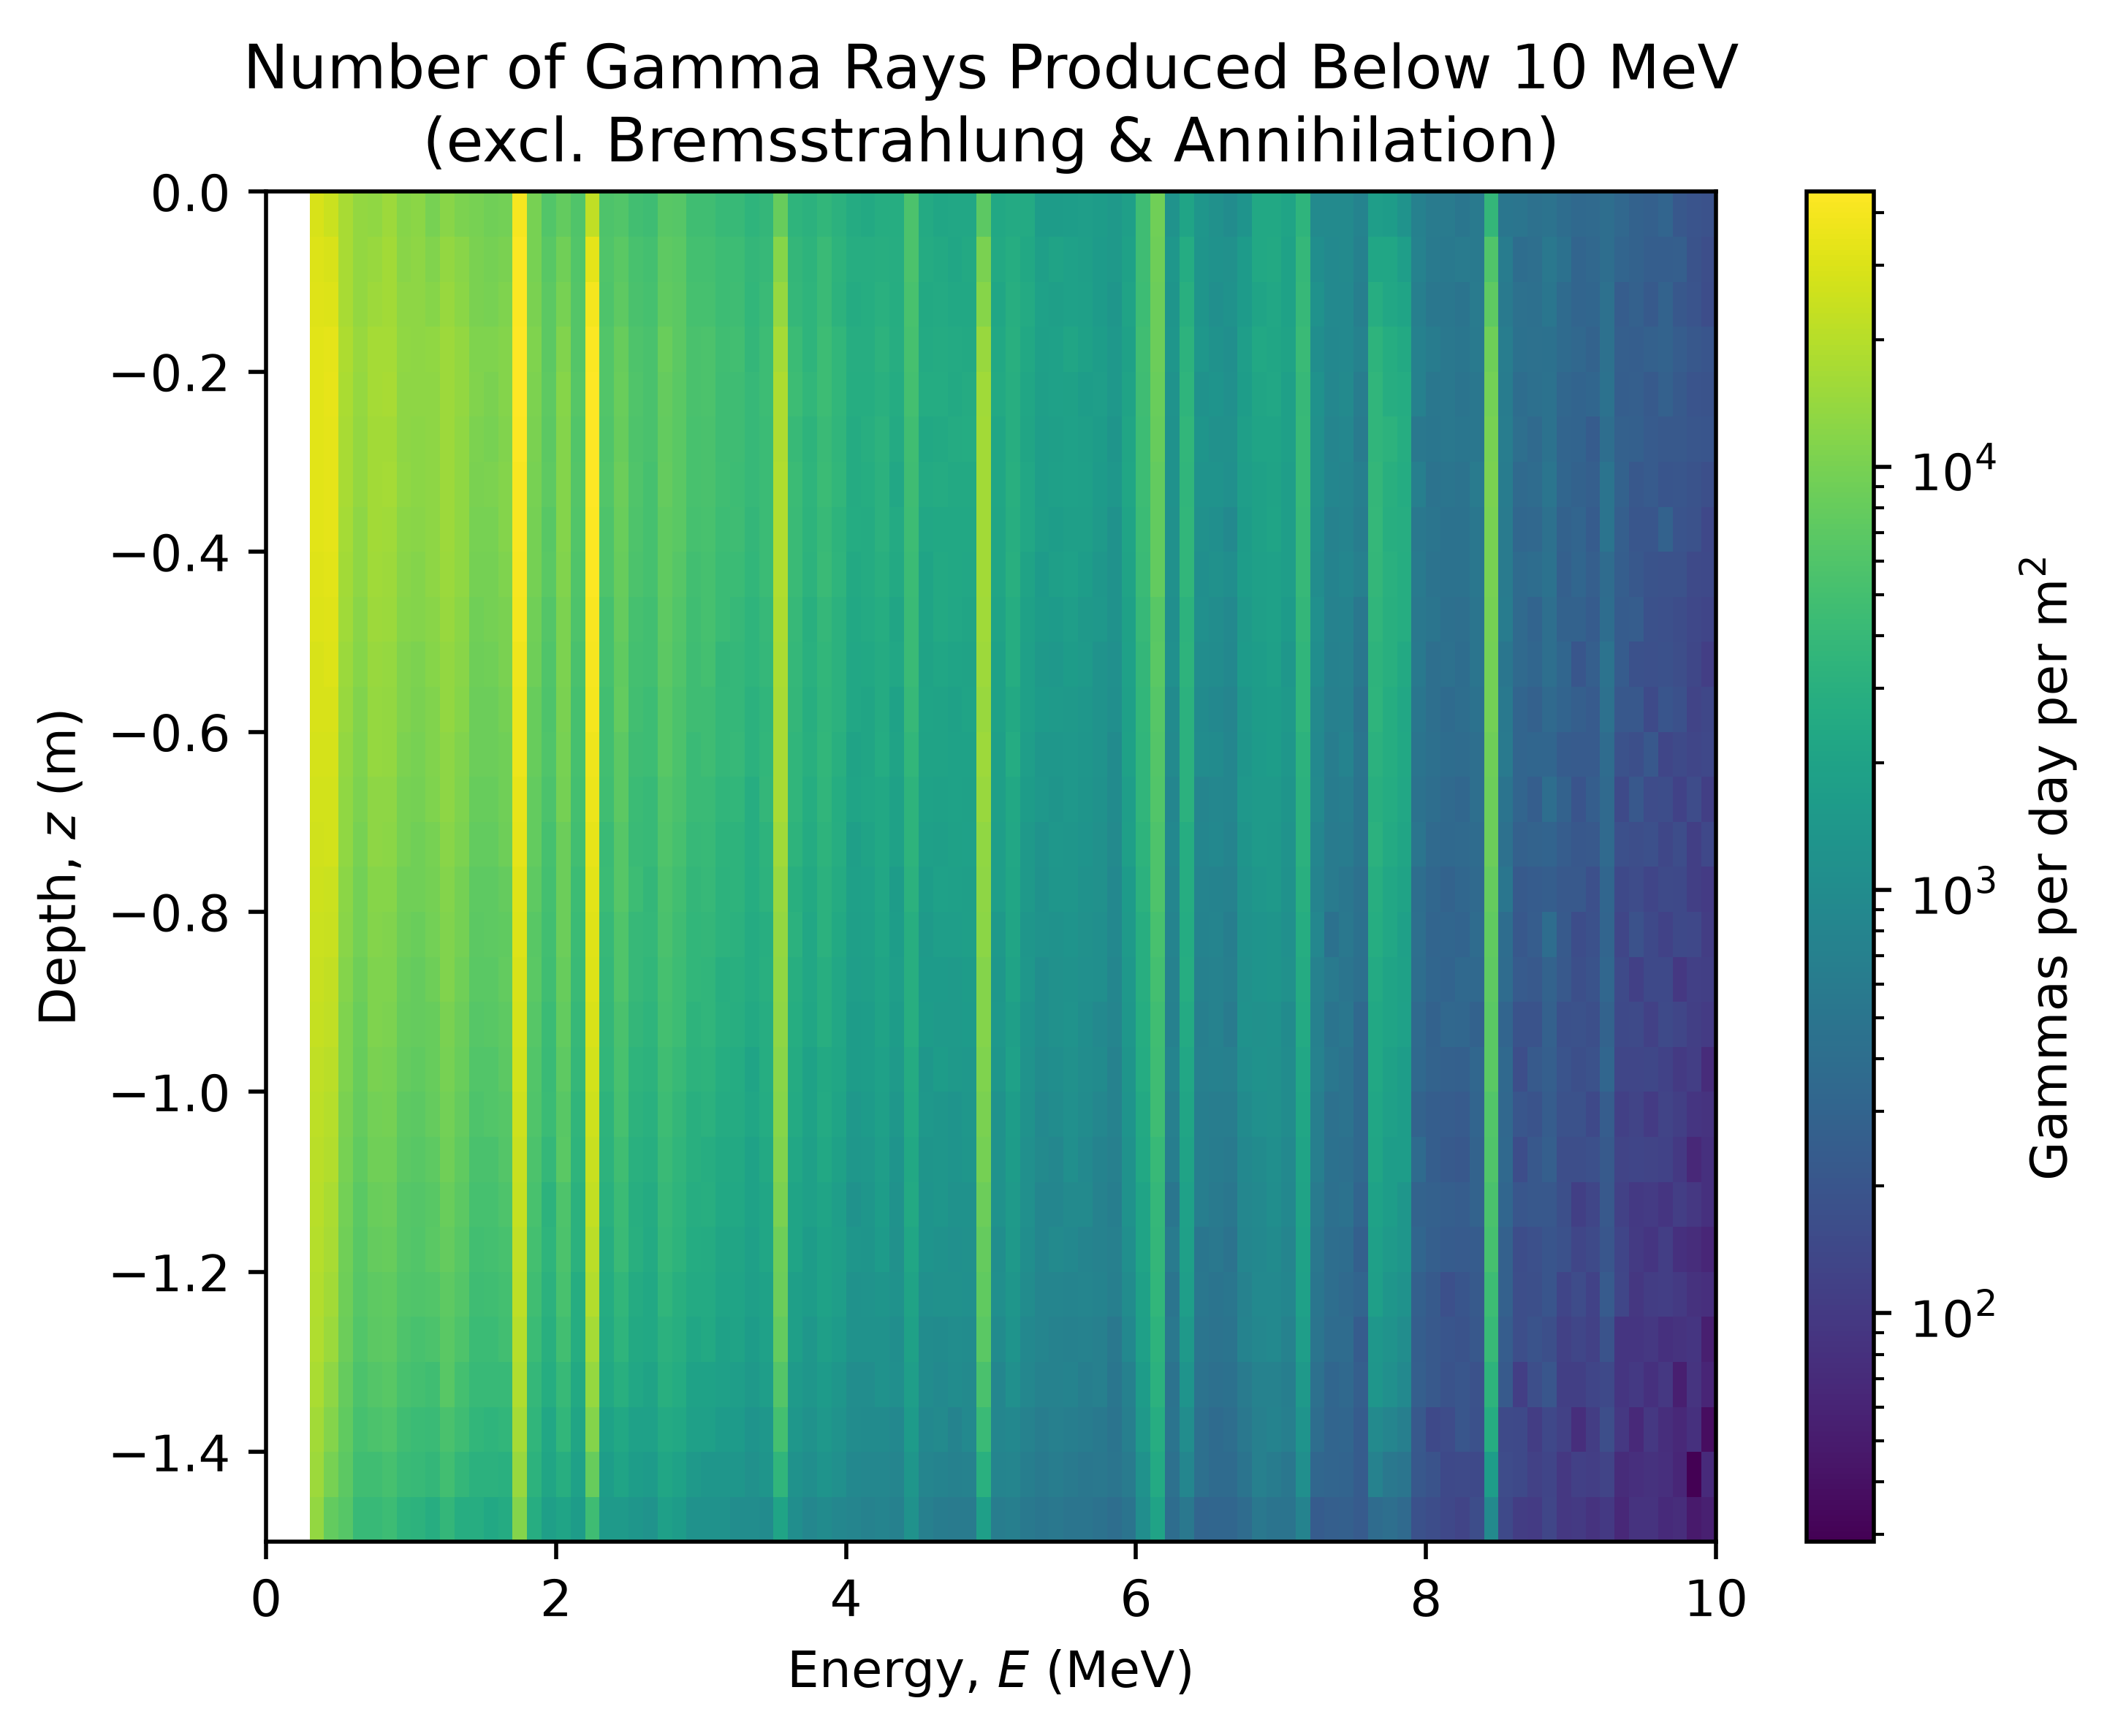

In [27]:
isotropic = exclude_processes(["em_other"])  # V4: the EM class holds bremsstrahlung and annihilation
mask = df["E"].between(0, 10) & isotropic
plt.hist2d(df[mask]["E"], df[mask]["z"] / 1e3, bins=(100, 30), range=((0, 10), (-1.5, 0)),
           weights=df[mask]["w"], norm=LogNorm())  # V4: binned data (5 cm depth bins), so hist2d not hexbin
plt.colorbar(label="Gammas per day per m$^2$")
plt.xlabel("Energy, $E$ (MeV)")
plt.ylabel("Depth, $z$ (m)")
plt.title(
    "Number of Gamma Rays Produced Below 10 MeV\n(excl. Bremsstrahlung & Annihilation)"
)
plt.show()

In [28]:
# Not available for V4: gamma directions are not in the reduced production data
# mask = df["E"].between(0, 10)
# plt.hexbin(df[mask]["p_z"], df[mask]["E"], linewidths=0.2, norm=LogNorm())
# plt.colorbar(label="Count")
# plt.xlabel("Momentum Angle Cosine, $\\cos \\theta$")
# plt.ylabel("Energy, $E$ (MeV)")
# plt.title("Number of Gamma Rays Produced Below 10 MeV")
# plt.show()

In [29]:
# Not available for V4: gamma directions are not in the reduced production data
# def plot_process(name, plot_type: Literal["prop", "num"] = "prop", mask=None):
#     plt.hexbin(
#         (df if mask is None else df[mask])["p_z"],
#         0.1 * (df if mask is None else df[mask])["z"],
#         linewidths=0.2,
#         C=include_processes([name], mask),
#         reduce_C_function=np.mean if plot_type == "prop" else np.sum,
#     )
#     type_str = "Proportion" if plot_type == "prop" else "Number"
#     plt.colorbar(label=type_str)
#     plt.xlabel("$z$-Momentum Bias, $p_z$")
#     plt.ylabel("Depth, $z$ (cm)")
#     plt.title(f"{type_str} of Gamma Rays Produced\nby {name}")
#     plt.show()

In [30]:
# Not available for V4: gamma directions are not in the reduced production data
# plot_process(
#     "eBrem",
#     plot_type="prop",
#     mask=df["E"].between(3, 1e10) & df["z"].between(-10000, 0),
# )

# V4: new in this campaign

The cells above are Jay's analysis run on the V4 production histograms. The sections below
cover what V4 added: the capture-model correction, soil-dependent births (five soil Orders and
SOC levels), the neutron flux tallies, and the physics-list and latitude variants.

## V4: capture correction

`V4CaptureModel` hands non-hydrogen captures to `G4NeutronHPCapture`, which re-samples the target
element, so a share p_H of them is re-emitted as hydrogen captures. On Geant4 11.3 (the campaign) this
makes the 2.223 MeV line ~1.5x too strong and every other capture line ~0.63x too weak. `v4lib`
measures p_H per run and corrects the capture classes (Final Data/v4_final/v4_analysis.ipynb, §3.1).
Every V4 number in this notebook uses the corrected births.

In [31]:
rows = []
h = CLASSES.index("capture_H")
for o in L.ORDERS:
    cc = L.capture_correction(o)
    raw = L.production_raw(o)[0][h, 2221:2225].sum() * DAY * 1e4
    rows.append((o, cc["p_h"], cc["k_h"], cc["k_cap"], raw, raw * cc["k_h"]))
pd.DataFrame(rows, columns=["Order", "p_H", "factor on capture_H", "factor on other captures",
                            "2.223 MeV births/day/m^2 (raw)", "(corrected)"]).round(3)

,Order,p_H,factor on capture_H,factor on other captures,2.223 MeV births/day/m^2 (raw),(corrected)
0,chromosol,0.367,0.676,1.580,1013372.684,684928.360
1,dermosol,0.376,0.679,1.603,1107909.107,752328.546
2,vertosol,0.417,0.694,1.716,1327971.841,921223.239
3,calcarosol,0.392,0.685,1.644,1168356.542,799870.109
4,kandosol,0.370,0.677,1.586,1041314.295,704756.534


## V4: births across soil Orders and SOC levels

V4 simulates five soil Orders at their geometric-mean composition and, for each, SOC scaled by
0.25, 0.5, 2 and 4 (SOC is the 0-30 cm dry-mass mean). Births are counted in the top 30 cm, which is
where most detected gammas come from (see analyse-transport, V4: depth of origin).

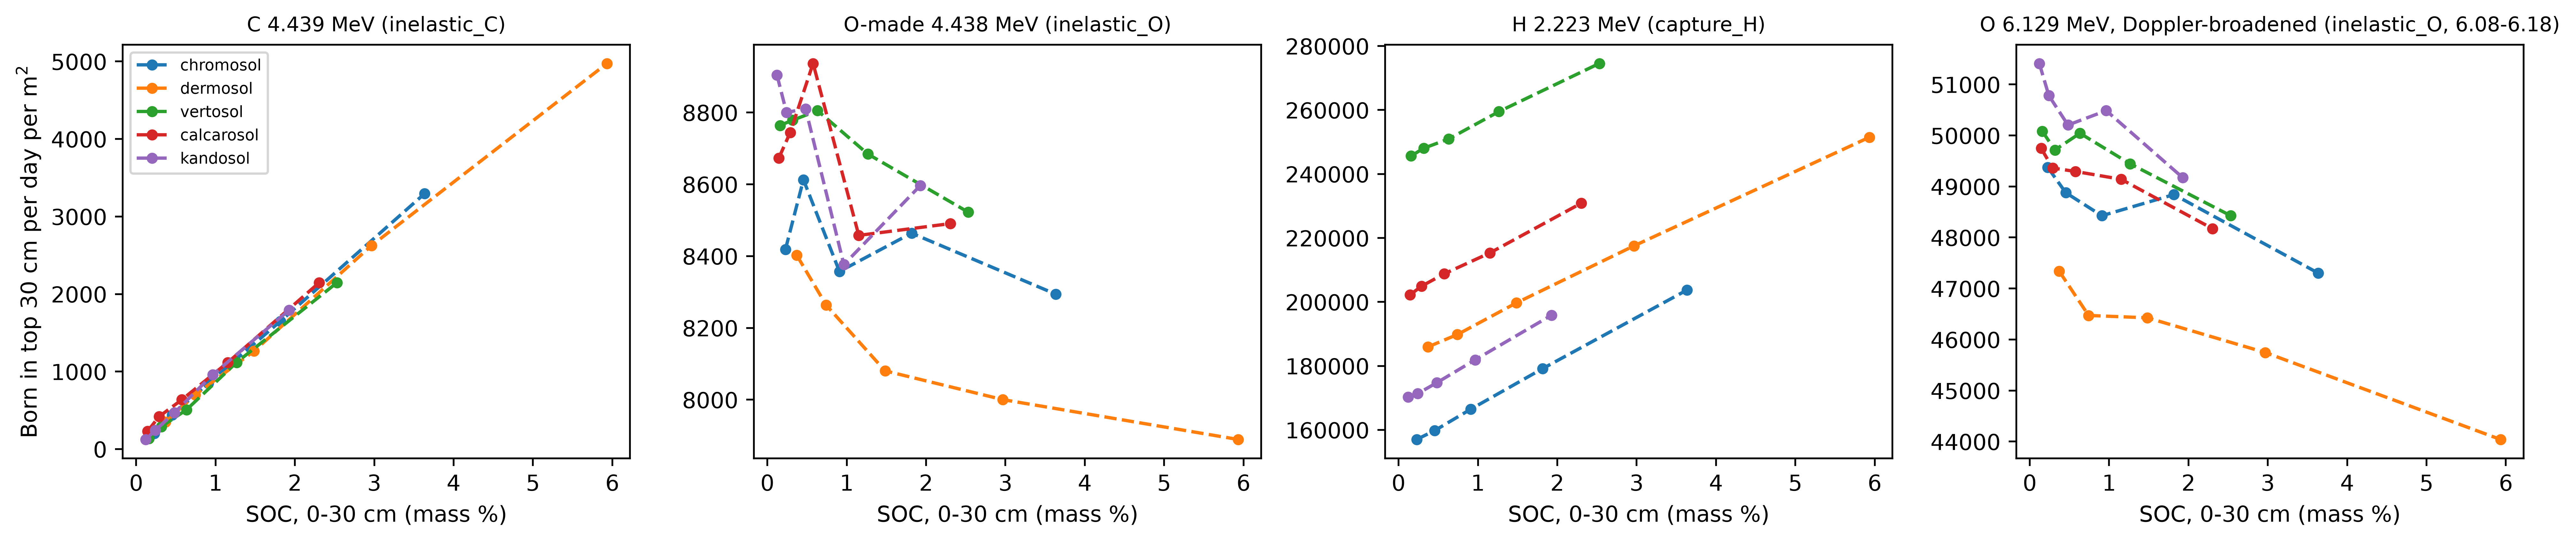

In [32]:
lines = {"C 4.439 MeV (inelastic_C)": (4439, 4440, ["inelastic_C"]),
         "O-made 4.438 MeV (inelastic_O)": (4438, 4439, ["inelastic_O"]),
         "H 2.223 MeV (capture_H)": (2223, 2224, ["capture_H"]),
         "O 6.129 MeV, Doppler-broadened (inelastic_O, 6.08-6.18)": (6080, 6180, ["inelastic_O"])}


def births_top30(rid, lo_kev, hi_kev, classes):
    ph, pdep = L.production(rid)
    idx = [CLASSES.index(c) for c in classes]
    top = pdep[idx, :, :6].sum(-1) / np.maximum(pdep[idx].sum(-1), 1e-300)  # share in 0-30 cm per 10 keV
    return float((ph[idx, lo_kev:hi_kev] * np.repeat(top, 10, axis=1)[:, lo_kev:hi_kev]).sum()) * DAY * 1e4


fig, axs = plt.subplots(1, len(lines), figsize=(16, 3.5))
for o in L.ORDERS:
    rids = [r for r in L.design_runs(o, "soc", extended=True) if not r.endswith("_rep")]
    soc = np.array([L.params(L.composition_id(r))["soc"] for r in rids])
    k = np.argsort(soc)
    for ax, (lab, (lo, hi, cls)) in zip(axs, lines.items()):
        b = np.array([births_top30(r, lo, hi, cls) for r in rids])
        ax.plot(soc[k], b[k], "o--", ms=4, label=o)
for ax, lab in zip(axs, lines):
    ax.set_title(lab, fontsize=9)
    ax.set_xlabel("SOC, 0-30 cm (mass %)")
axs[0].set_ylabel("Born in top 30 cm per day per m$^2$")
axs[0].legend(fontsize=7)
plt.tight_layout()
plt.show()

## V4: neutron field

V4 tallies the neutron track length by depth and energy in every production run, in the soil and in
the air above it. The capture lines (2.223 MeV H, Si, Fe) follow the thermal flux, and the inelastic
lines (C, O) follow the fast flux. Water is the strongest moderator, so the water variants are shown
with the SOC extremes.

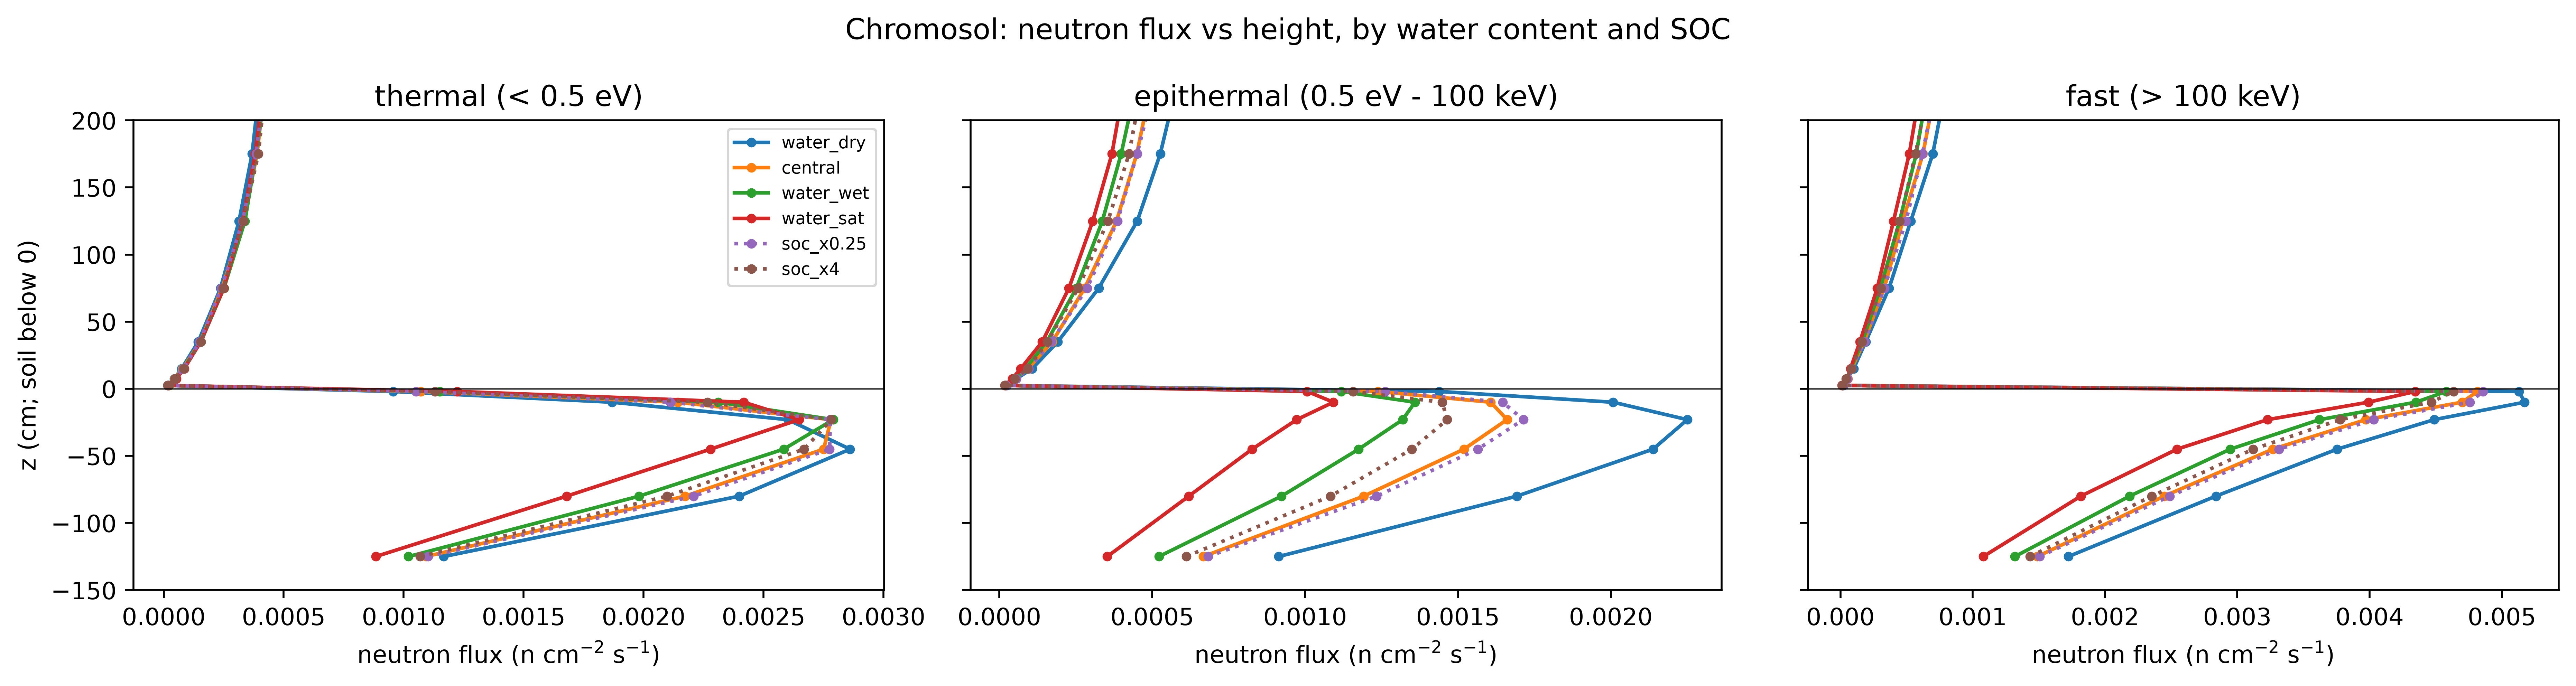

,0-30 cm thermal (< 0.5 eV),0-30 cm epithermal (0.5 eV - 100 keV),0-30 cm fast (> 100 keV)
run,,,
chromosol_water_dry,0.00201,0.00195,0.00438
chromosol,0.00223,0.00152,0.00395
chromosol_water_wet,0.00232,0.00127,0.00365
chromosol_water_sat,0.00232,0.001,0.00333
chromosol_soc_x0.25,0.00221,0.00156,0.00401
chromosol_soc_x4,0.00229,0.00137,0.00377


In [33]:
edges = L.FLUX_Z_EDGES
zc = 0.5 * (edges[:-1] + edges[1:])
loge = L.FLUX_LOGE_EDGES
groups = {"thermal (< 0.5 eV)": (-10, np.log10(0.5e-6)), "epithermal (0.5 eV - 100 keV)": (np.log10(0.5e-6), -1),
          "fast (> 100 keV)": (-1, 4)}
runs = ["chromosol_water_dry", "chromosol", "chromosol_water_wet", "chromosol_water_sat",
        "chromosol_soc_x0.25", "chromosol_soc_x4"]
fig, axs = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
# The tally books each step to one 2 cm bin, which piles fast-neutron track length onto the soil
# layer boundaries; averaging over each soil layer (0-5, 5-15, 15-30, 30-60, 60-100, 100-150 cm) removes it.
dz = np.diff(edges)
layers = [-150, -100, -60, -30, -15, -5, 0]
soil_groups = [np.nonzero((edges[:-1] >= a) & (edges[1:] <= b))[0] for a, b in zip(layers[:-1], layers[1:])]
air = np.nonzero(edges[:-1] >= 0)[0]
zc_plot = np.array([zc[g].mean() for g in soil_groups] + list(zc[air]))


def coarse(profile):
    return np.array([(profile[g] * dz[g]).sum() / dz[g].sum() for g in soil_groups] + list(profile[air]))


for r in runs:
    f = L.neutron_flux(r)
    for ax, (g, (a, b)) in zip(axs, groups.items()):
        m = (loge[:-1] >= a) & (loge[:-1] < b)
        ax.plot(coarse(f[:, m].sum(1)), zc_plot, marker=".", ls="-" if "soc" not in r else ":", label=r.replace("chromosol_", "").replace("chromosol", "central"))
for ax, g in zip(axs, groups):
    ax.set_title(g)
    ax.set_xlabel("neutron flux (n cm$^{-2}$ s$^{-1}$)")
    ax.axhline(0, color="k", lw=0.5)
axs[0].set_ylim(-150, 200)
axs[0].set_ylabel("z (cm; soil below 0)")
axs[0].legend(fontsize=7)
plt.suptitle("Chromosol: neutron flux vs height, by water content and SOC")
plt.tight_layout()
plt.show()

rows = []
for r in runs:
    f = L.neutron_flux(r)
    top = (edges[:-1] >= -30) & (edges[1:] <= 0)
    dz = np.diff(edges)[top]
    rows.append([r] + [float((f[top][:, (loge[:-1] >= a) & (loge[:-1] < b)].sum(1) * dz).sum() / dz.sum())
                       for a, b in groups.values()])
pd.DataFrame(rows, columns=["run"] + [f"0-30 cm {g}" for g in groups]).set_index("run").map(lambda v: f"{v:.3g}")

## V4: physics-list and latitude variants

Each variant changes one thing about the Chromosol central run. The table gives births per day per m²
in the whole soil column, as ratios to the central run. The error is Poisson on the simulated counts,
inflated for the several gammas each shower makes.

In [34]:
variants = ["phys_qgsp", "phys_ts", "phys_capdefault", "chromosol_lat_north", "chromosol_lat_south", "chromosol_rep"]
lines_all = {"C 4.439": (4439, 4440, None), "O 6.129 (6.08-6.18, inelastic_O)": (6080, 6180, ["inelastic_O"]), "H 2.223": (2223, 2224, None),
             "Si 3.539 (capture)": (3539, 3540, None), "all > 0.3 MeV": (300, 12000, None)}
rows = []
for r in variants:
    row = {"run": r, "change": L.info(r)["run"]["change"]}
    for lab, (lo, hi, cls) in lines_all.items():
        a, sa = L.births(r, lo, hi, cls), L.births_sigma(r, lo, hi, cls)
        b, sb = L.births("chromosol", lo, hi, cls), L.births_sigma("chromosol", lo, hi, cls)
        row[lab] = f"{a / b:.3f} ± {a / b * np.hypot(sa / a, sb / b):.3f}"
    rows.append(row)
pd.DataFrame(rows).set_index("run")

,change,C 4.439,"O 6.129 (6.08-6.18, inelastic_O)",H 2.223,Si 3.539 (capture),all > 0.3 MeV
run,,,,,,
phys_qgsp,hadronic physics QGSP_BIC_HP,1.046 ± 0.056,0.824 ± 0.009,0.819 ± 0.004,0.826 ± 0.008,0.966 ± 0.000
phys_ts,thermal scattering law for H in water,0.975 ± 0.053,1.006 ± 0.010,1.024 ± 0.005,1.021 ± 0.010,1.002 ± 0.000
phys_capdefault,capture model left at the physics list default...,0.986 ± 0.054,1.000 ± 0.010,0.999 ± 0.005,1.000 ± 0.010,1.001 ± 0.000
chromosol_lat_north,CRY latitude -12.46,0.828 ± 0.047,0.692 ± 0.008,0.702 ± 0.004,0.700 ± 0.007,0.879 ± 0.000
chromosol_lat_south,CRY latitude -42.88,1.065 ± 0.057,1.190 ± 0.011,1.183 ± 0.005,1.184 ± 0.011,1.039 ± 0.000
chromosol_rep,"central, independent seed (MC reproducibility)",0.998 ± 0.054,1.009 ± 0.010,1.003 ± 0.005,1.003 ± 0.010,1.001 ± 0.000
